<center><h1>Gong_Jiale_HW4</h1></center>
<br>
<br>

Name: Jiale Gong
<br>
Github Username: jialegong
<br>
USC ID: 1387502580

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import os
import io
import zipfile
import requests
from scipy.stats import bootstrap
import numpy as np
import pandas as pd
from collections import Counter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

Get the AReM Data Set

In [3]:
url = (
    "https://archive.ics.uci.edu/static/public/366/"
    "activity+recognition+system+based+on+multisensor+"
    "data+fusion+arem.zip"
)
ALL_COLUMNS = ["time", "avg_rss12", "var_rss12", "avg_rss13",
               "var_rss13", "avg_rss23", "var_rss23"]
SERIES_NAMES = ["avg_rss12", "var_rss12", "avg_rss13",
                "var_rss13", "avg_rss23", "var_rss23"]
ACTIVITIES = ["bending1", "bending2", "cycling", "lying",
              "sitting", "standing", "walking"]


print("Downloading AReM Dataset")

response = requests.get(url)
response.raise_for_status()
print("Status code:", response.status_code)
print("Downloaded file size:", len(response.content), "bytes")
def parse_arem_csv(csv_bytes, expected_rows=480):
    text = csv_bytes.decode("utf-8", errors="replace")
    data_rows = []
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        line = line.rstrip(",").strip()
        if "," in line:
            fields = [f.strip() for f in line.split(",")]
        else:
            fields = line.split()
        fields = [f for f in fields if f != ""]
        if len(fields) != len(ALL_COLUMNS):
            continue
        data_rows.append(fields)

    if len(data_rows) == 0:
        raise ValueError("No valid data rows were found")

    df = pd.DataFrame(data_rows, columns=ALL_COLUMNS)
    df = df.apply(pd.to_numeric, errors="coerce")

    if df.isna().any().any():
        raise ValueError("Non-numeric values remain after cleaning")

    if len(df) < expected_rows:
        df = df.reindex(range(expected_rows)).ffill().bfill()
    elif len(df) > expected_rows:
        df = df.iloc[:expected_rows].reset_index(drop=True)

    return df
instances = []
with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    for name in archive.namelist():
        if not name.endswith(".csv"):
            continue
        folder = name.split("/")[0]
        if folder not in ACTIVITIES:
            continue
        df = parse_arem_csv(archive.read(name))
        instances.append((folder, name, df))

print("\nTotal instances:", len(instances))
print("Shapes found:", {df.shape for _, _, df in instances})

counts = Counter(label for label, _, _ in instances)
print("\nInstances per activity:")
for activity in ACTIVITIES:
    print(f"  {activity:<10}: {counts[activity]}")

label, name, df = instances[0]
print(f"\nExample: {name}")
print(f"Shape: {df.shape}")
print(df.head().to_string(index=False))

cleaning_summary = pd.DataFrame({
    "File": ["bending2/dataset4.csv", "cycling/dataset9.csv",
             "cycling/dataset14.csv", "sitting/dataset8.csv"],
    "Problem": ["Whitespace-separated instead of comma-separated",
                "Extra trailing comma", "Extra trailing comma",
                "Only 479 rows"],
    "Cleaning Method": ["Split on whitespace", "Remove trailing comma",
                        "Remove trailing comma", "Forward-fill to 480 rows"],
})
print("\nData Cleaning Summary:")
print(cleaning_summary.to_string(index=False))

Status code: 200
Downloaded file size: 524200 bytes

Total instances: 88
Shapes found: {(480, 7)}

Instances per activity:
  bending1  : 7
  bending2  : 6
  cycling   : 15
  lying     : 15
  sitting   : 15
  standing  : 15
  walking   : 15

Example: bending1/dataset1.csv
Shape: (480, 7)
 time  avg_rss12  var_rss12  avg_rss13  var_rss13  avg_rss23  var_rss23
    0      39.25       0.43      22.75       0.43      33.75        1.3
  250      39.25       0.43      23.00       0.00      33.00        0.0
  500      39.25       0.43      23.25       0.43      33.00        0.0
  750      39.50       0.50      23.00       0.71      33.00        0.0
 1000      39.50       0.50      24.00       0.00      33.00        0.0

Data Cleaning Summary:
                 File                                         Problem          Cleaning Method
bending2/dataset4.csv Whitespace-separated instead of comma-separated      Split on whitespace
 cycling/dataset9.csv                            Extra trailing co

In [5]:
def parse_strict_csv(csv_bytes, expected_rows=480):
    text = csv_bytes.decode("utf-8", errors="replace")
    rows = []
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith("#"):
            continue
        fields = [f.strip() for f in line.split(",")]
        if len(fields) != len(ALL_COLUMNS) or any(f == "" for f in fields):
            raise ValueError("Invalid fields")
        rows.append(fields)
    if len(rows) != expected_rows:
        raise ValueError("Wrong row count")
    df = pd.DataFrame(rows, columns=ALL_COLUMNS)
    return df.apply(pd.to_numeric, errors="raise")

instances_skipped, skipped_files = [], []
with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
    for name in archive.namelist():
        if not name.endswith(".csv"):
            continue
        folder = name.split("/")[0]
        if folder not in ACTIVITIES:
            continue
        try:
            df_s = parse_strict_csv(archive.read(name))
            instances_skipped.append((folder, name, df_s))
        except (ValueError, TypeError):
            skipped_files.append(name)

print("\nSkipped files:", skipped_files)
print("Instances without cleaning:", len(instances_skipped))

def split(inst_list):
    train, test = [], []
    for label, fname, df in inst_list:
        n = int(os.path.basename(fname).replace("dataset", "").replace(".csv", ""))
        is_test = (n in [1, 2]) if label in ["bending1", "bending2"] else (n in [1, 2, 3])
        (test if is_test else train).append((label, fname, df))
    return train, test

def feats(df):
    v = []
    for c in SERIES_NAMES:
        s = df[c].to_numpy()
        v += [np.min(s), np.max(s), np.mean(s), np.median(s),
              np.std(s, ddof=1), np.percentile(s, 25), np.percentile(s, 75)]
    return v

def to_arrays(inst_list):
    X, y = [], []
    for label, _, df in inst_list:
        X.append(feats(df)); y.append(label)
    return np.array(X), np.array(y)

tr_A, te_A = split(instances_skipped)
XA_tr, yA_tr = to_arrays(tr_A); XA_te, yA_te = to_arrays(te_A)
rf_A = RandomForestClassifier(n_estimators=200, random_state=42).fit(XA_tr, yA_tr)
acc_A = accuracy_score(yA_te, rf_A.predict(XA_te))

tr_B, te_B = split(instances)
XB_tr, yB_tr = to_arrays(tr_B); XB_te, yB_te = to_arrays(te_B)
rf_B = RandomForestClassifier(n_estimators=200, random_state=42).fit(XB_tr, yB_tr)
acc_B = accuracy_score(yB_te, rf_B.predict(XB_te))

print("\nImpact of Data Cleaning")
print(f"  A: Skip problematic files: {len(instances_skipped)} instances | "
      f"Train {len(tr_A)} / Test {len(te_A)} | Acc = {acc_A:.4f}")
print(f"  B: Clean all files:        {len(instances)} instances | "
      f"Train {len(tr_B)} / Test {len(te_B)} | Acc = {acc_B:.4f}")
print(f"  Difference: {acc_B - acc_A:+.4f}")


Skipped files: ['bending2/dataset4.csv', 'cycling/dataset14.csv', 'cycling/dataset9.csv', 'sitting/dataset8.csv']
Instances without cleaning: 84

Impact of Data Cleaning
  A: Skip problematic files: 84 instances | Train 65 / Test 19 | Acc = 0.8947
  B: Clean all files:        88 instances | Train 69 / Test 19 | Acc = 0.8947
  Difference: +0.0000


### (b) Splitting Data

In [7]:
train_instances = []
test_instances = []

for label, fname, df in instances:
    base = os.path.basename(fname)                              # e.g. "dataset3.csv"
    dataset_num = int(base.replace("dataset", "").replace(".csv", ""))

    if label in ["bending1", "bending2"]:
        is_test = dataset_num in [1, 2]
    else:
        is_test = dataset_num in [1, 2, 3]

    if is_test:
        test_instances.append((label, fname, df))
    else:
        train_instances.append((label, fname, df))

print(f"Training instances: {len(train_instances)}")
print(f"Test instances:     {len(test_instances)}")

train_counts = Counter(label for label, _, _ in train_instances)
test_counts  = Counter(label for label, _, _ in test_instances)

print("\nTrain/Test distribution per activity:")
print(f"{'Activity':<10} {'Train':>6} {'Test':>6}")
print("-" * 26)
for activity in ACTIVITIES:
    print(f"{activity:<10} {train_counts[activity]:>6} {test_counts[activity]:>6}")
print("-" * 26)
print(f"{'Total':<10} {len(train_instances):>6} {len(test_instances):>6}")

Training instances: 69
Test instances:     19

Train/Test distribution per activity:
Activity    Train   Test
--------------------------
bending1        5      2
bending2        4      2
cycling        12      3
lying          12      3
sitting        12      3
standing       12      3
walking        12      3
--------------------------
Total          69     19


### (c) Feature Extraction

In [9]:
SERIES_NAMES = ["avg_rss12", "var_rss12", "avg_rss13",
                "var_rss13", "avg_rss23", "var_rss23"]

FEATURE_NAMES = ["min", "max", "mean", "median", "std", "q1", "q3"]


def extract_features(series):
    """Extract 7 time-domain features from one time series."""
    return [
        np.min(series),
        np.max(series),
        np.mean(series),
        np.median(series),
        np.std(series, ddof=1),
        np.percentile(series, 25),
        np.percentile(series, 75),
    ]


def instance_to_vector(df):
    """Convert one instance (6 series) into a 42-dim feature vector."""
    vec = []
    for col in SERIES_NAMES:
        vec.extend(extract_features(df[col].values))
    return vec


feature_col_names = [f"{col}_{feat}"
                     for col in SERIES_NAMES
                     for feat in FEATURE_NAMES]
def build_dataset(instance_list):
    X, y = [], []
    for label, fname, df in instance_list:
        X.append(instance_to_vector(df))
        y.append(label)
    return np.array(X), np.array(y)


X_train, y_train = build_dataset(train_instances)
X_test,  y_test  = build_dataset(test_instances)

print("Feature Extraction")

print(f"Training feature matrix: {X_train.shape}")
print(f"Test feature matrix:     {X_test.shape}")


X_all, y_all = build_dataset(instances)

df_all_features = pd.DataFrame(X_all, columns=feature_col_names)

instance_names = [
    f"{label}/{os.path.basename(fname)}"
    for label, fname, _ in instances
]

df_all_features.insert(0, "instance", instance_names)
df_all_features.insert(1, "label", y_all)

print("\nComplete numerical feature matrix:", X_all.shape)
print("Complete dataset including instance and label:",
      df_all_features.shape)

print("\nComplete feature table:")
print("Shape:", df_all_features.shape)

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None
):
    display(df_all_features)

Feature Extraction
Training feature matrix: (69, 42)
Test feature matrix:     (19, 42)

Complete numerical feature matrix: (88, 42)
Complete dataset including instance and label: (88, 44)

Complete feature table:
Shape: (88, 44)


,instance,label,avg_rss12_min,avg_rss12_max,avg_rss12_mean,avg_rss12_median,avg_rss12_std,avg_rss12_q1,avg_rss12_q3,var_rss12_min,var_rss12_max,var_rss12_mean,var_rss12_median,var_rss12_std,var_rss12_q1,var_rss12_q3,avg_rss13_min,avg_rss13_max,avg_rss13_mean,avg_rss13_median,avg_rss13_std,avg_rss13_q1,avg_rss13_q3,var_rss13_min,var_rss13_max,var_rss13_mean,var_rss13_median,var_rss13_std,var_rss13_q1,var_rss13_q3,avg_rss23_min,avg_rss23_max,avg_rss23_mean,avg_rss23_median,avg_rss23_std,avg_rss23_q1,avg_rss23_q3,var_rss23_min,var_rss23_max,var_rss23_mean,var_rss23_median,var_rss23_std,var_rss23_q1,var_rss23_q3
0,bending1/dataset1.csv,bending1,37.25,45.00,40.624792,40.500,1.476967,39.2500,42.0000,0.0,1.30,0.358604,0.430,0.322605,0.0000,0.5000,4.00,29.50,19.040937,19.250,4.462952,16.0000,23.2500,0.0,7.23,0.832542,0.500,0.965659,0.0000,1.1200,27.25,38.25,34.311292,35.000,2.188449,33.0000,36.0000,0.00,1.92,0.570583,0.430,0.582915,0.0000,1.3000
1,bending1/dataset2.csv,bending1,38.00,45.67,42.812812,42.500,1.435550,42.0000,43.6700,0.0,1.22,0.372437,0.470,0.289158,0.0000,0.5000,2.00,29.50,20.096979,21.000,3.893737,19.0000,22.2500,0.0,5.76,0.876438,0.500,1.047259,0.0000,1.1450,27.67,38.50,33.024583,33.000,1.995255,32.0000,34.5000,0.00,3.11,0.571083,0.430,0.601010,0.0000,1.3000
2,bending1/dataset3.csv,bending1,35.00,47.40,43.954500,44.330,1.558835,43.0000,45.0000,0.0,1.70,0.426250,0.470,0.338690,0.0000,0.5000,6.50,29.75,22.122354,23.000,3.030943,19.7500,24.0000,0.0,4.44,0.497312,0.430,0.550657,0.0000,0.8300,29.00,38.50,35.588458,36.000,1.999604,35.3625,36.5000,0.00,1.79,0.493292,0.430,0.513506,0.0000,0.9400
3,bending1/dataset4.csv,bending1,33.00,47.75,42.179812,43.500,3.670666,39.1500,45.0000,0.0,3.00,0.696042,0.500,0.630860,0.0000,1.1200,8.50,30.00,22.183625,23.000,3.810469,20.5000,24.3725,0.0,5.15,0.989917,0.830,0.953730,0.4300,1.3000,20.00,38.67,33.493917,35.000,3.849448,30.4575,36.3300,0.00,2.18,0.613521,0.500,0.524317,0.0000,1.0000
4,bending1/dataset5.csv,bending1,33.00,45.75,41.678063,41.750,2.243490,41.3300,42.7500,0.0,2.83,0.535979,0.500,0.405469,0.4300,0.7100,3.00,28.25,19.006563,19.125,4.087107,16.5000,22.0625,0.0,6.42,0.841875,0.500,0.928801,0.4300,1.1200,23.67,37.50,29.857083,30.000,2.411026,28.4575,31.2500,0.00,1.79,0.383292,0.430,0.389164,0.0000,0.5000
5,bending1/dataset6.csv,bending1,37.00,48.00,43.454958,43.250,1.386098,42.5000,45.0000,0.0,1.58,0.378083,0.470,0.315566,0.0000,0.5000,5.75,27.00,15.793333,15.000,3.847638,13.0000,18.2700,0.0,10.03,0.849354,0.500,0.995761,0.4300,1.1200,8.00,33.50,23.034792,23.500,2.488862,22.2500,24.0000,0.00,5.26,0.679646,0.500,0.622534,0.4300,0.8700
6,bending1/dataset7.csv,bending1,36.25,48.00,43.969125,44.500,1.618364,43.3100,44.6700,0.0,1.50,0.413125,0.470,0.263111,0.4300,0.5000,1.50,26.33,15.868021,16.250,3.742420,14.2500,18.0000,0.0,5.17,0.666354,0.470,0.788985,0.0000,0.9400,11.33,30.75,22.103750,21.670,3.318301,20.5000,23.7500,0.00,2.96,0.555312,0.490,0.487826,0.0000,0.8300
7,bending2/dataset1.csv,bending2,12.75,51.00,24.562958,24.250,3.737514,23.1875,26.5000,0.0,6.87,0.590833,0.430,0.837408,0.0000,0.7100,0.00,25.33,19.121333,20.250,4.299612,18.0000,22.0000,0.0,6.76,0.736771,0.470,0.927048,0.0000,0.8700,10.67,30.00,23.493042,23.750,3.693786,20.5000,27.0000,0.00,4.97,0.700188,0.500,0.693720,0.4300,0.8700
8,bending2/dataset2.csv,bending2,0.00,42.75,27.464604,28.000,3.583582,25.5000,30.0000,0.0,7.76,0.449708,0.430,0.767197,0.0000,0.5000,7.50,35.00,20.842542,20.750,3.826268,18.0000,22.5000,0.0,5.76,0.779917,0.500,0.904436,0.0000,0.9400,0.00,33.00,17.617938,18.000,5.053642,15.0000,20.7500,0.00,6.76,1.122125,0.830,1.012342,0.4700,1.3000
9,bending2/dataset3.csv,bending2,21.00,50.00,32.586208,33.000,6.238143,26.1875,34.5000,0.0,9.90,0.516125,0.430,0.789957,0.0000,0.8225,0.00,28.25,13.941625,14.250,5.883266,10.0000,18.0000,0.0,7.40,0.868896,0.500,1.027013,0.4300,1.1200,5.00,33.75,20.345708,19.585,5.032424,17.6700,23.5000,0.00,13.61,1.162042,0.830,1.332980,0.4700,1.3000


In [11]:
feature_stds = np.std(X_all, axis=0, ddof=1)


def sample_std(x, axis=-1):
    """Sample standard deviation used in bootstrap."""
    return np.std(x, axis=axis, ddof=1)


ci_results = []

N_RESAMPLES = 1000
CONFIDENCE = 0.90

for j, feature_name in enumerate(feature_col_names):
    data = X_all[:, j]
    std_est = feature_stds[j]

    # Handle features that are constant across all instances
    if np.isclose(std_est, 0.0):
        ci_results.append({
            "feature": feature_name,
            "std_estimate": 0.0,
            "ci_low": 0.0,
            "ci_high": 0.0,
            "ci_width": 0.0,
            "note": "degenerate"
        })
        continue
    result = bootstrap(
        (data,),
        sample_std,
        vectorized=True,
        confidence_level=CONFIDENCE,
        n_resamples=N_RESAMPLES,
        method="BCa",
        random_state=42
    )

    ci_low = result.confidence_interval.low
    ci_high = result.confidence_interval.high

    ci_results.append({
        "feature": feature_name,
        "std_estimate": std_est,
        "ci_low": ci_low,
        "ci_high": ci_high,
        "ci_width": ci_high - ci_low,
        "note": ""
    })


ci_df = pd.DataFrame(ci_results)

# Display all 42 features
display(ci_df.round(4))

degenerate_features = ci_df.loc[
    ci_df["note"] == "degenerate", "feature"
].tolist()

print("Number of features:", len(ci_df))
print("Degenerate features:", degenerate_features)

ci_df.to_csv("arem_bootstrap_ci.csv", index=False)

,feature,std_estimate,ci_low,ci_high,ci_width,note
0,avg_rss12_min,9.5700,8.5854,11.3051,2.7197,
1,avg_rss12_max,4.3944,3.6006,5.5267,1.9261,
2,avg_rss12_mean,5.3357,4.8252,6.0457,1.2205,
3,avg_rss12_median,5.4401,4.8666,6.1393,1.2727,
4,avg_rss12_std,1.7722,1.6157,1.9823,0.3666,
5,avg_rss12_q1,6.1536,5.6278,6.7263,1.0986,
6,avg_rss12_q3,5.1389,4.4482,5.9580,1.5098,
7,var_rss12_min,0.0000,0.0000,0.0000,0.0000,degenerate
8,var_rss12_max,5.0627,4.6770,5.4678,0.7908,
9,var_rss12_mean,1.5742,1.4272,1.7255,0.2983,


Number of features: 42
Degenerate features: ['var_rss12_min', 'var_rss13_min']


In [13]:
selected_feature_types = [
    "mean",
    "std",
    "max"
]

print("Selected time-domain feature types:")

for i, feature in enumerate(
    selected_feature_types,
    start=1
):
    print(f"{i}. {feature}")


selected_feature_columns = [
    f"{series}_{feature}"
    for series in SERIES_NAMES
    for feature in selected_feature_types
]

selected_feature_indices = [
    feature_col_names.index(column)
    for column in selected_feature_columns
]


X_all, y_all = build_dataset(instances)

X_selected = X_all[
    :,
    selected_feature_indices
]

df_selected_features = pd.DataFrame(
    X_selected,
    columns=selected_feature_columns
)
instance_names = [
    f"{label}/{os.path.basename(file_name)}"
    for label, file_name, _ in instances
]

df_selected_features.insert(
    0,
    "instance",
    instance_names
)

df_selected_features.insert(
    1,
    "label",
    y_all
)



print(
    "\nNumber of selected feature types:",
    len(selected_feature_types)
)

print(
    "Number of selected numerical features:",
    X_selected.shape[1]
)

print(
    "Shape of selected feature matrix:",
    X_selected.shape
)

display(df_selected_features.head())

Selected time-domain feature types:
1. mean
2. std
3. max

Number of selected feature types: 3
Number of selected numerical features: 18
Shape of selected feature matrix: (88, 18)


,instance,label,avg_rss12_mean,avg_rss12_std,avg_rss12_max,var_rss12_mean,var_rss12_std,var_rss12_max,avg_rss13_mean,avg_rss13_std,avg_rss13_max,var_rss13_mean,var_rss13_std,var_rss13_max,avg_rss23_mean,avg_rss23_std,avg_rss23_max,var_rss23_mean,var_rss23_std,var_rss23_max
0,bending1/dataset1.csv,bending1,40.624792,1.476967,45.00,0.358604,0.322605,1.30,19.040937,4.462952,29.50,0.832542,0.965659,7.23,34.311292,2.188449,38.25,0.570583,0.582915,1.92
1,bending1/dataset2.csv,bending1,42.812812,1.435550,45.67,0.372437,0.289158,1.22,20.096979,3.893737,29.50,0.876438,1.047259,5.76,33.024583,1.995255,38.50,0.571083,0.601010,3.11
2,bending1/dataset3.csv,bending1,43.954500,1.558835,47.40,0.426250,0.338690,1.70,22.122354,3.030943,29.75,0.497312,0.550657,4.44,35.588458,1.999604,38.50,0.493292,0.513506,1.79
3,bending1/dataset4.csv,bending1,42.179812,3.670666,47.75,0.696042,0.630860,3.00,22.183625,3.810469,30.00,0.989917,0.953730,5.15,33.493917,3.849448,38.67,0.613521,0.524317,2.18
4,bending1/dataset5.csv,bending1,41.678063,2.243490,45.75,0.535979,0.405469,2.83,19.006563,4.087107,28.25,0.841875,0.928801,6.42,29.857083,2.411026,37.50,0.383292,0.389164,1.79


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

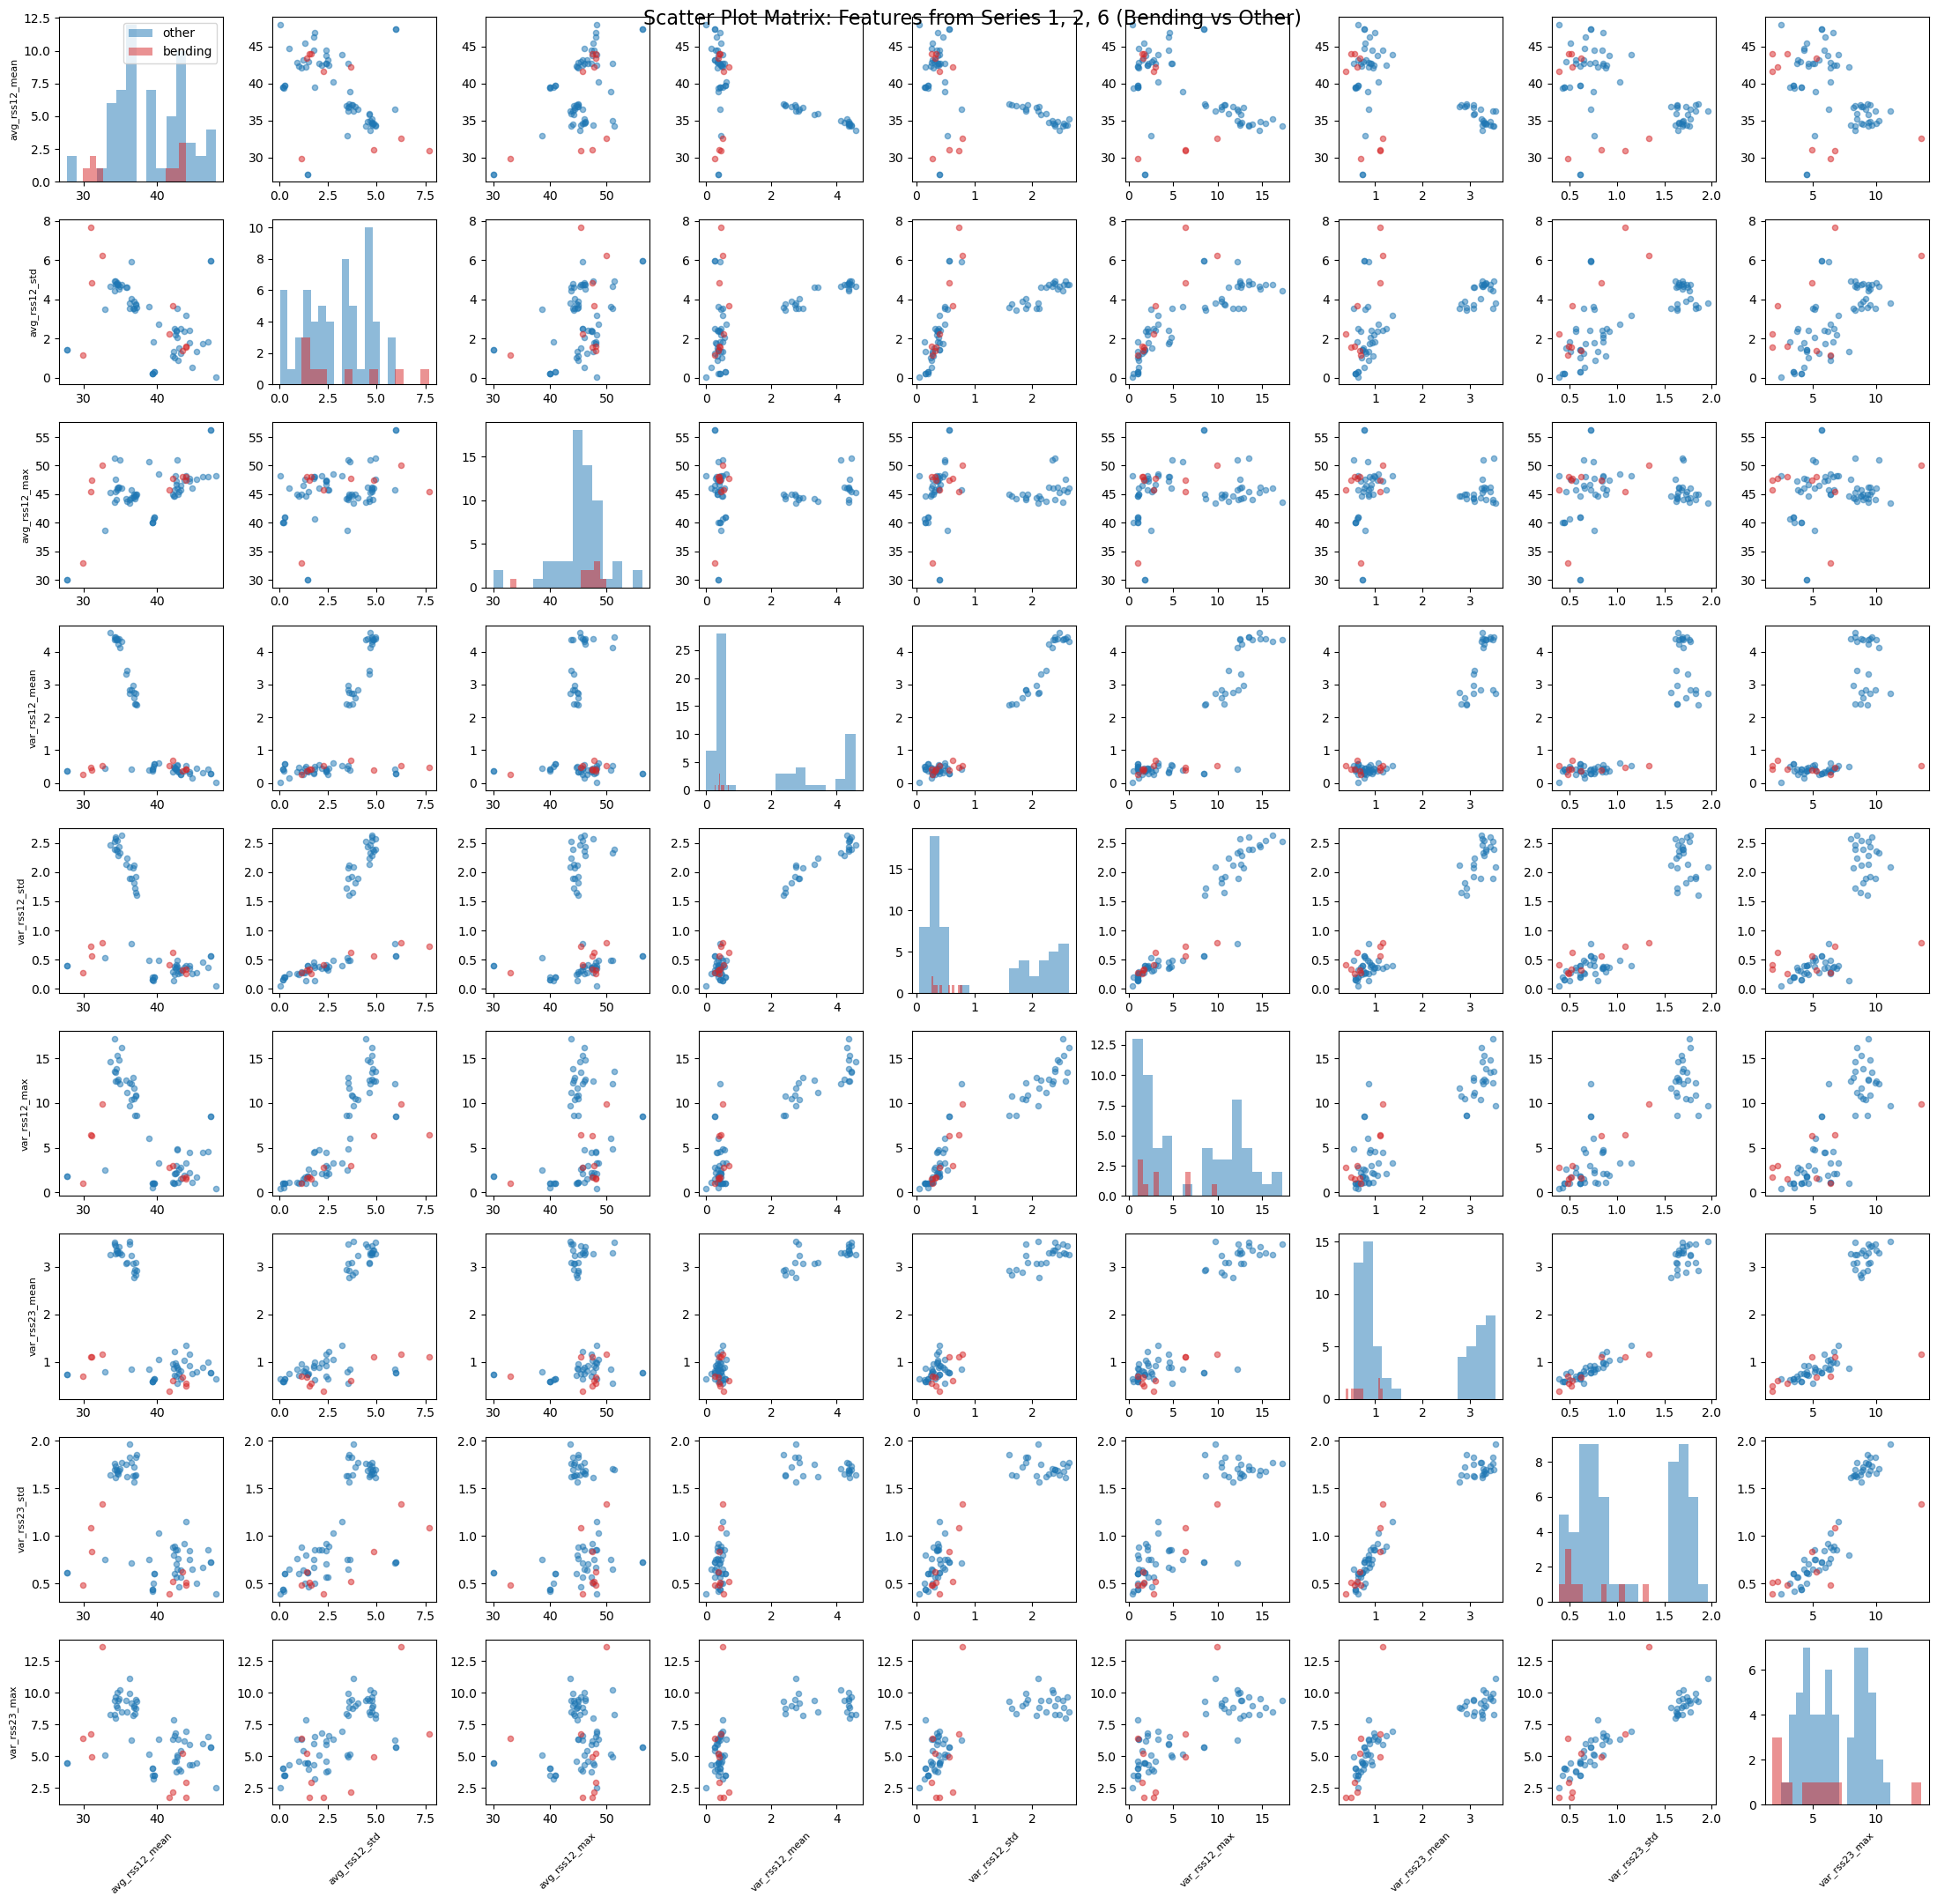

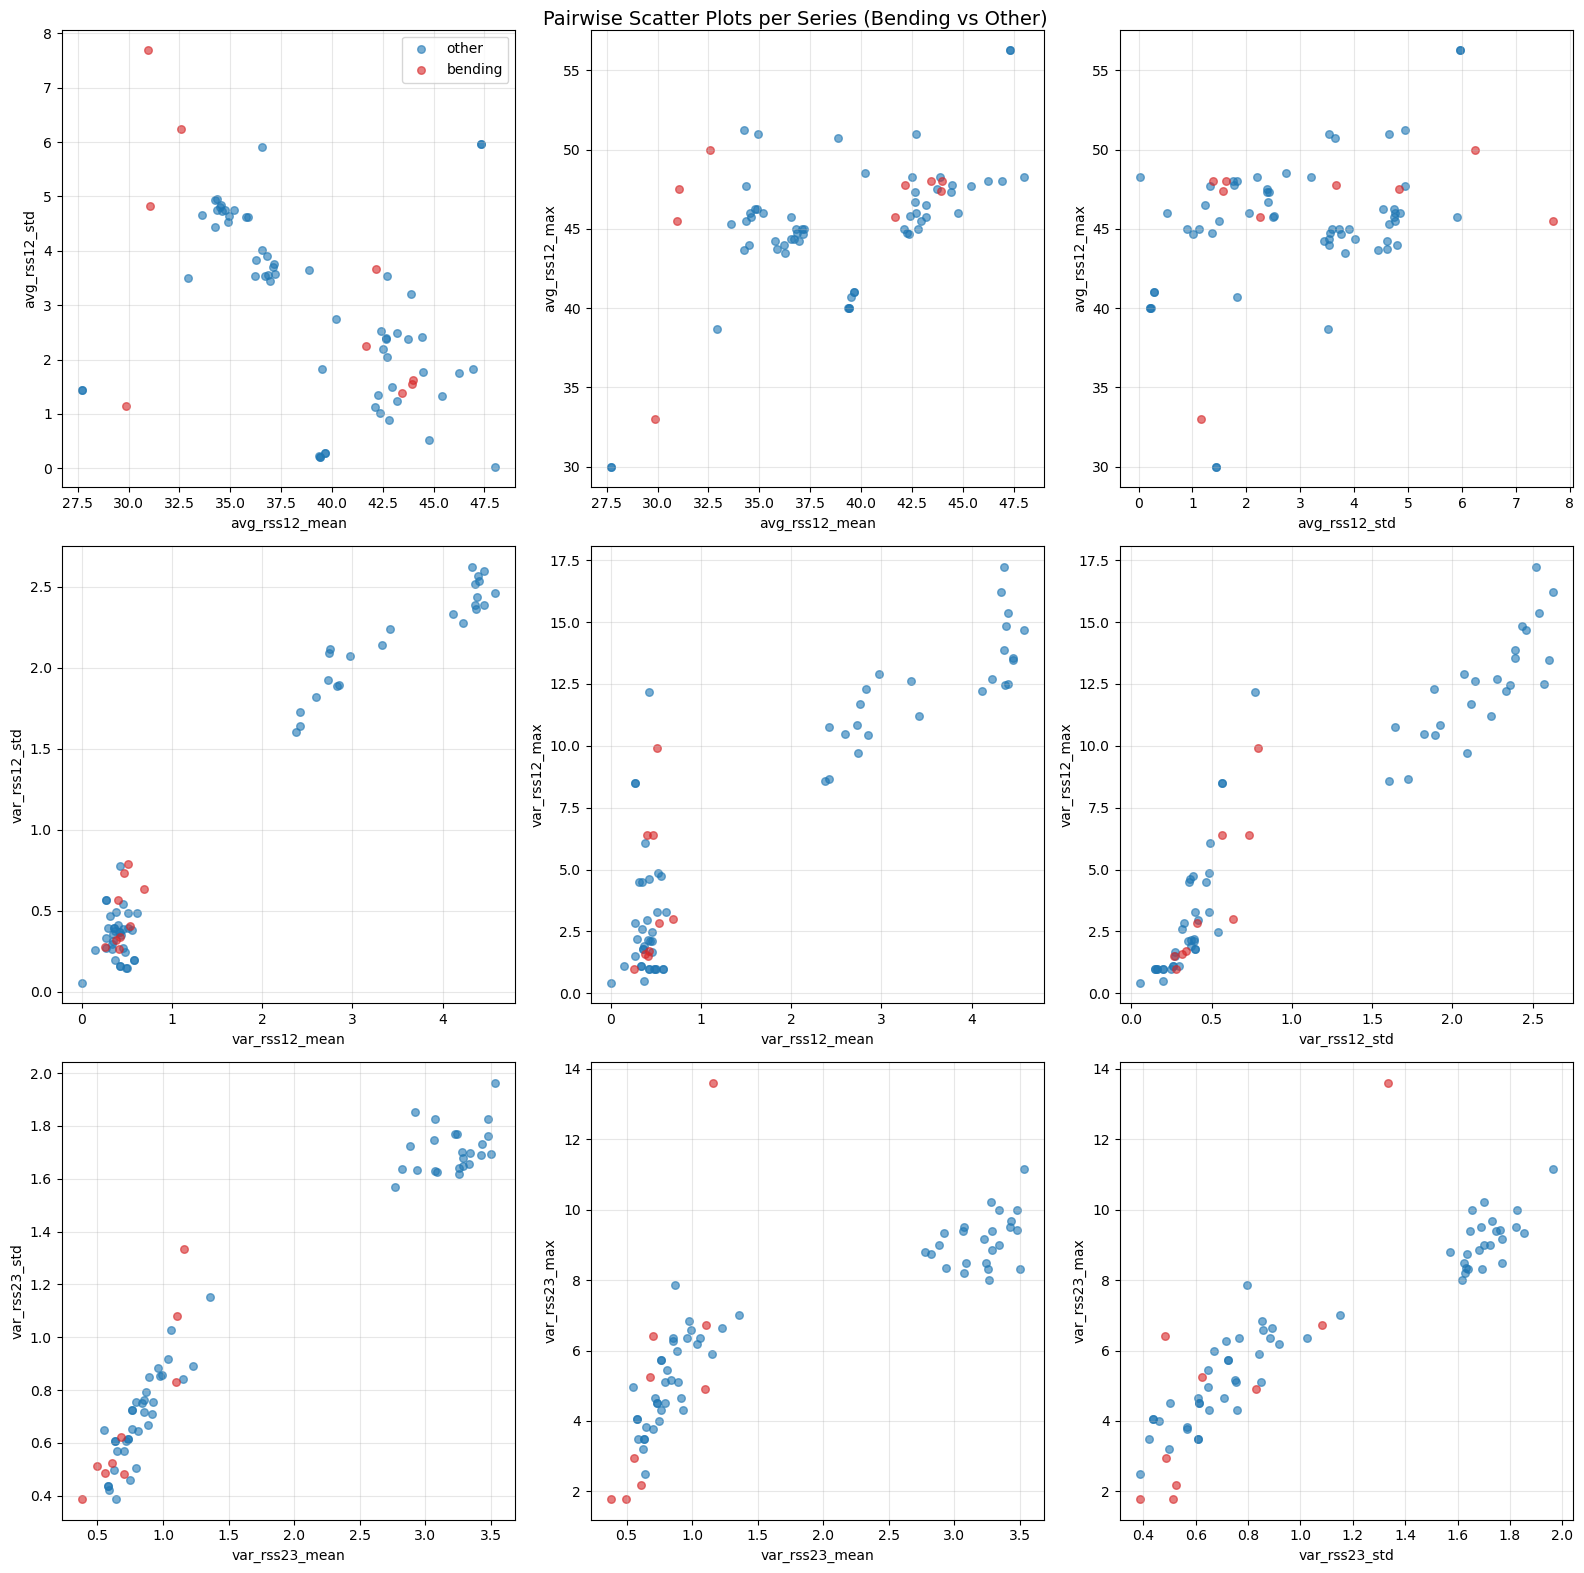

In [17]:
import matplotlib.pyplot as plt
y_binary = np.array([
    "bending" if label.startswith("bending") else "other"
    for label in y_train
])

SERIES_1_2_6 = ["avg_rss12", "var_rss12", "var_rss23"]
SELECTED_FEATS = ["mean", "std", "max"]

plot_features = []
for series in SERIES_1_2_6:
    for feat in SELECTED_FEATS:
        col = f"{series}_{feat}"
        idx = feature_col_names.index(col)
        plot_features.append((col, idx))

n = len(plot_features)          # 9 features
colors = {"other": "tab:blue", "bending": "tab:red"}

fig, axes = plt.subplots(n, n, figsize=(22, 22))

for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        if i == j:
            # Diagonal: histogram
            for label in ["other", "bending"]:
                mask = y_binary == label
                ax.hist(X_train[mask, plot_features[i][1]],
                        bins=15, alpha=0.5,
                        color=colors[label], label=label)
        else:
            for label in ["other", "bending"]:
                mask = y_binary == label
                ax.scatter(X_train[mask, plot_features[j][1]],
                           X_train[mask, plot_features[i][1]],
                           c=colors[label], alpha=0.5, s=20)

        if i == n - 1:
            ax.set_xlabel(plot_features[j][0], fontsize=8, rotation=45)
        if j == 0:
            ax.set_ylabel(plot_features[i][0], fontsize=8)

axes[0, 0].legend(loc="upper right")
plt.suptitle("Scatter Plot Matrix: Features from Series 1, 2, 6 "
             "(Bending vs Other)", fontsize=16)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(16, 16))

feature_pairs = [
    ("mean", "std"),
    ("mean", "max"),
    ("std",  "max"),
]

for row, series in enumerate(SERIES_1_2_6):
    for col, (f1, f2) in enumerate(feature_pairs):
        ax = axes[row, col]
        idx1 = feature_col_names.index(f"{series}_{f1}")
        idx2 = feature_col_names.index(f"{series}_{f2}")

        for label in ["other", "bending"]:
            mask = y_binary == label
            ax.scatter(X_train[mask, idx1],
                       X_train[mask, idx2],
                       c=colors[label], alpha=0.6, s=30, label=label)

        ax.set_xlabel(f"{series}_{f1}")
        ax.set_ylabel(f"{series}_{f2}")
        ax.grid(True, alpha=0.3)
        if row == 0 and col == 0:
            ax.legend()

plt.suptitle("Pairwise Scatter Plots per Series (Bending vs Other)",
             fontsize=14)
plt.tight_layout()
plt.show()

#### ii. Splitted Plots

Split training matrix: (69, 18)


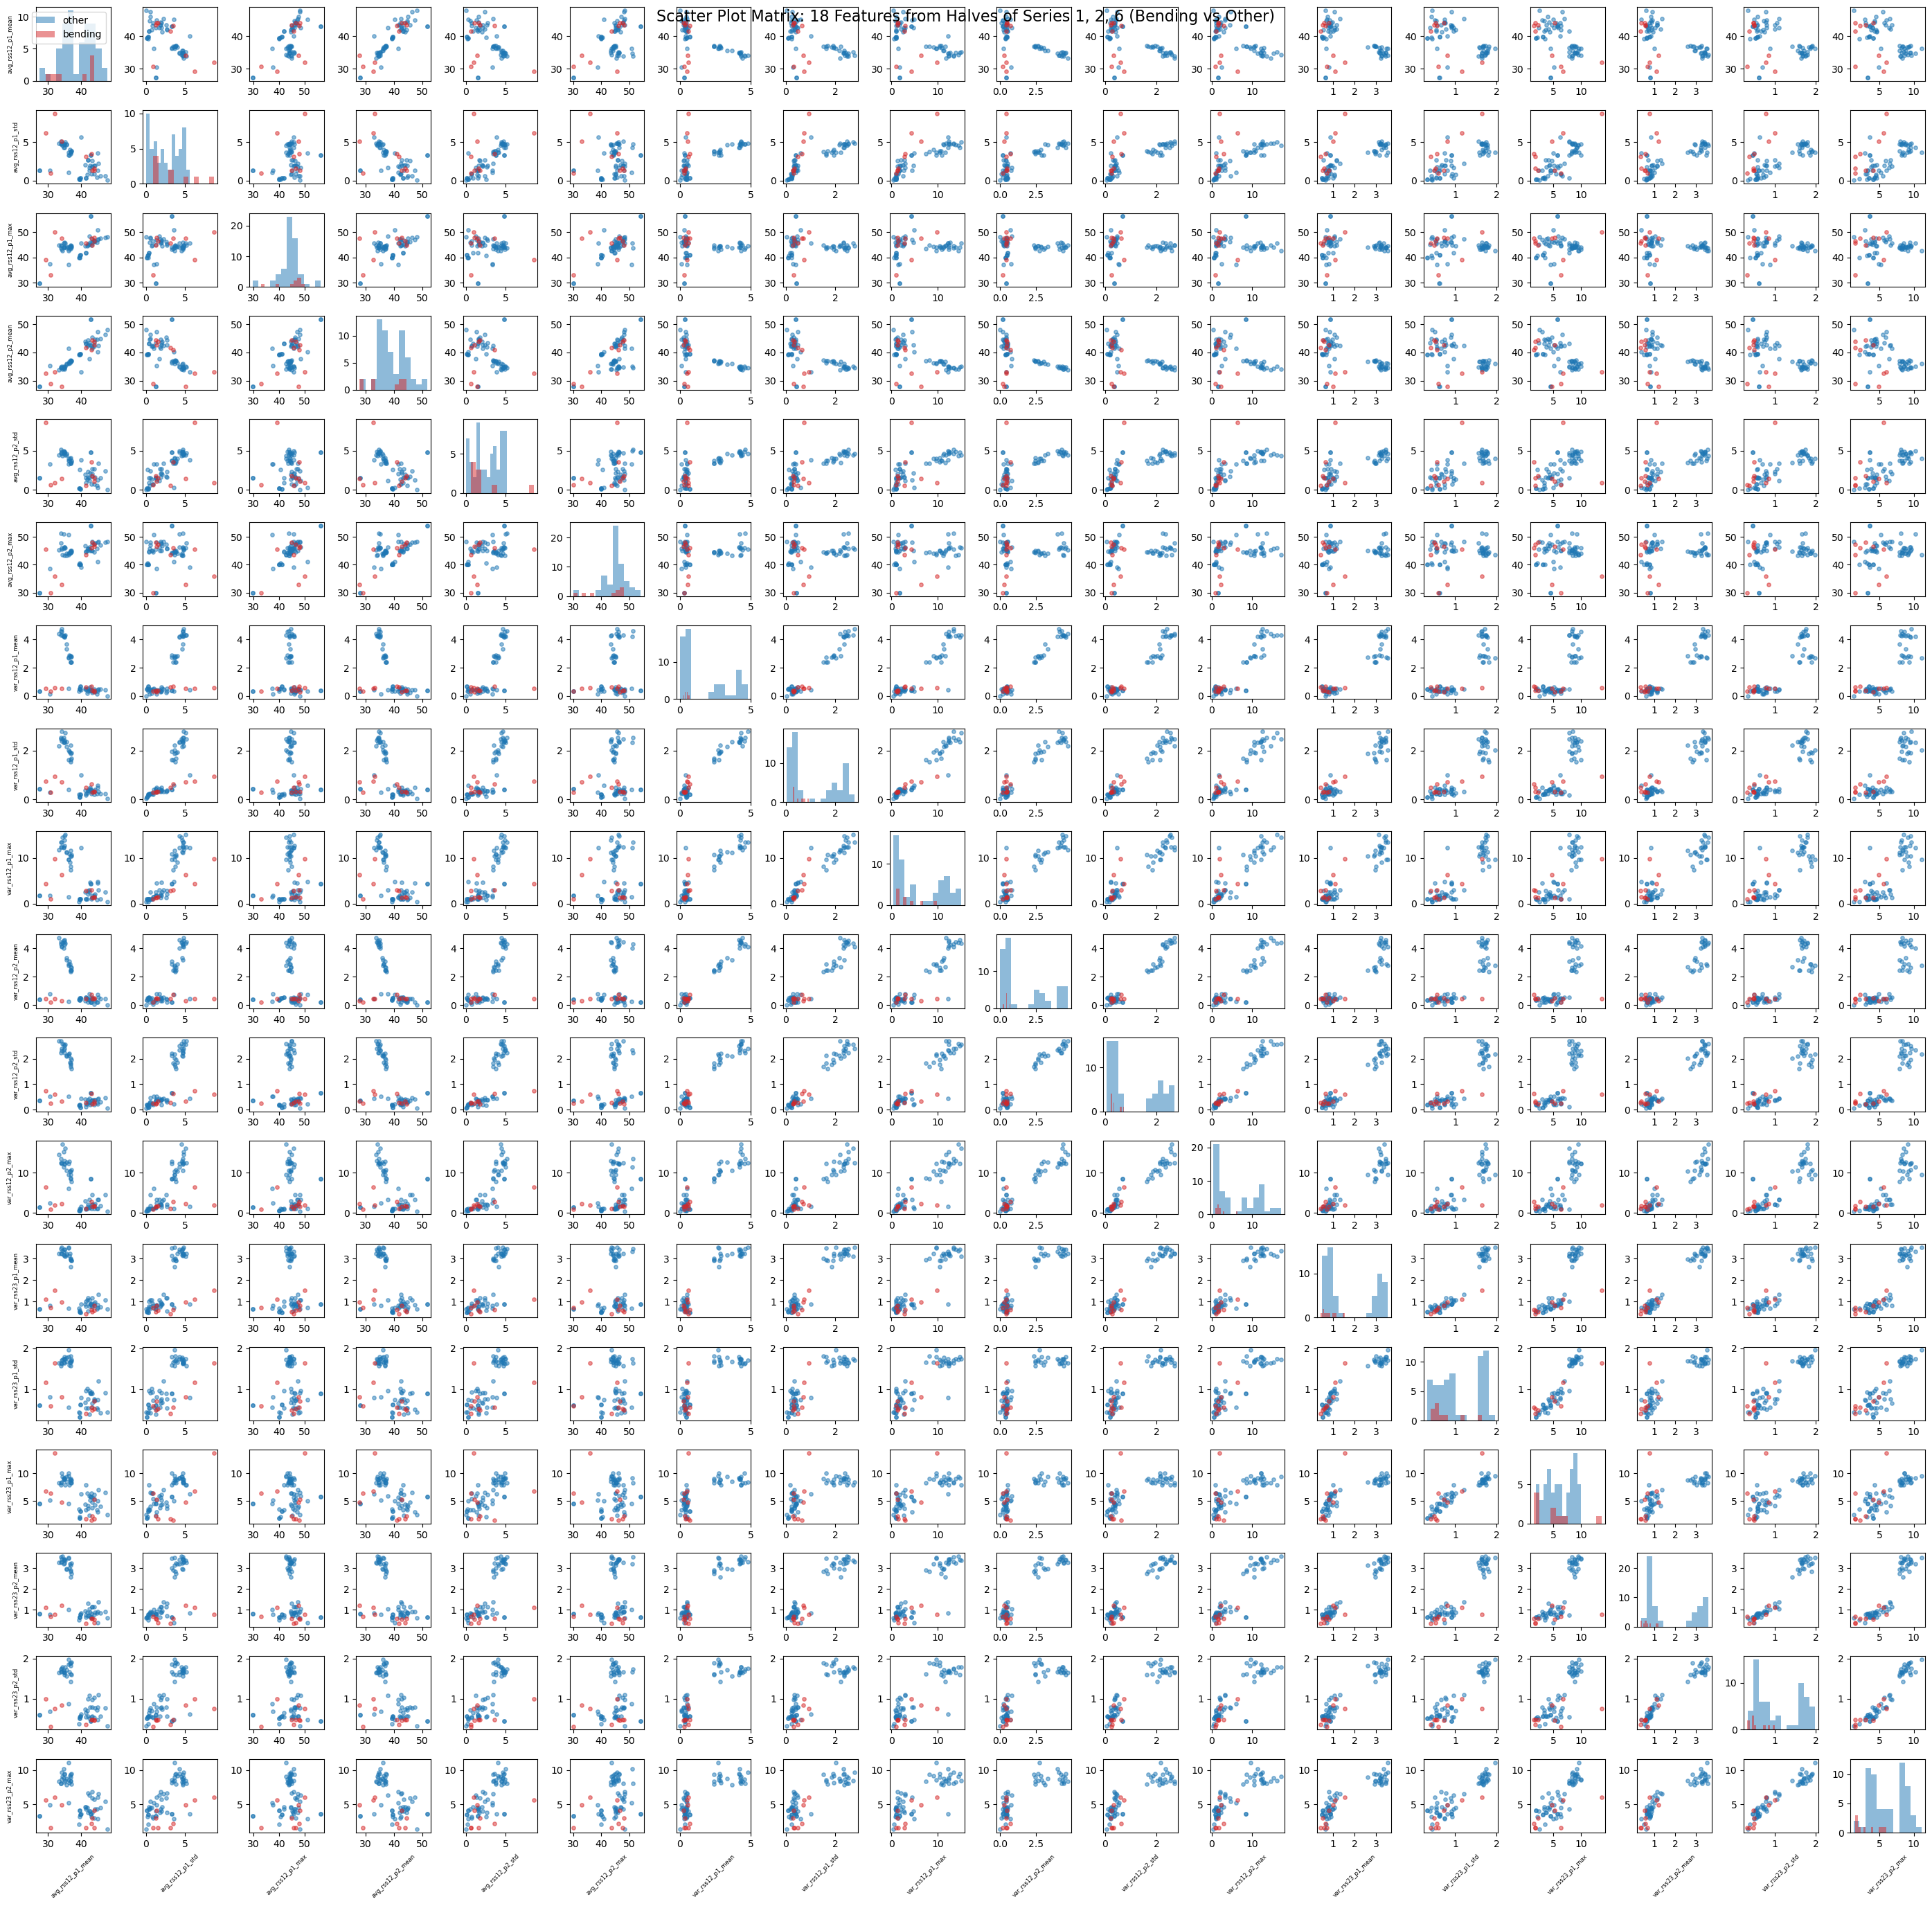

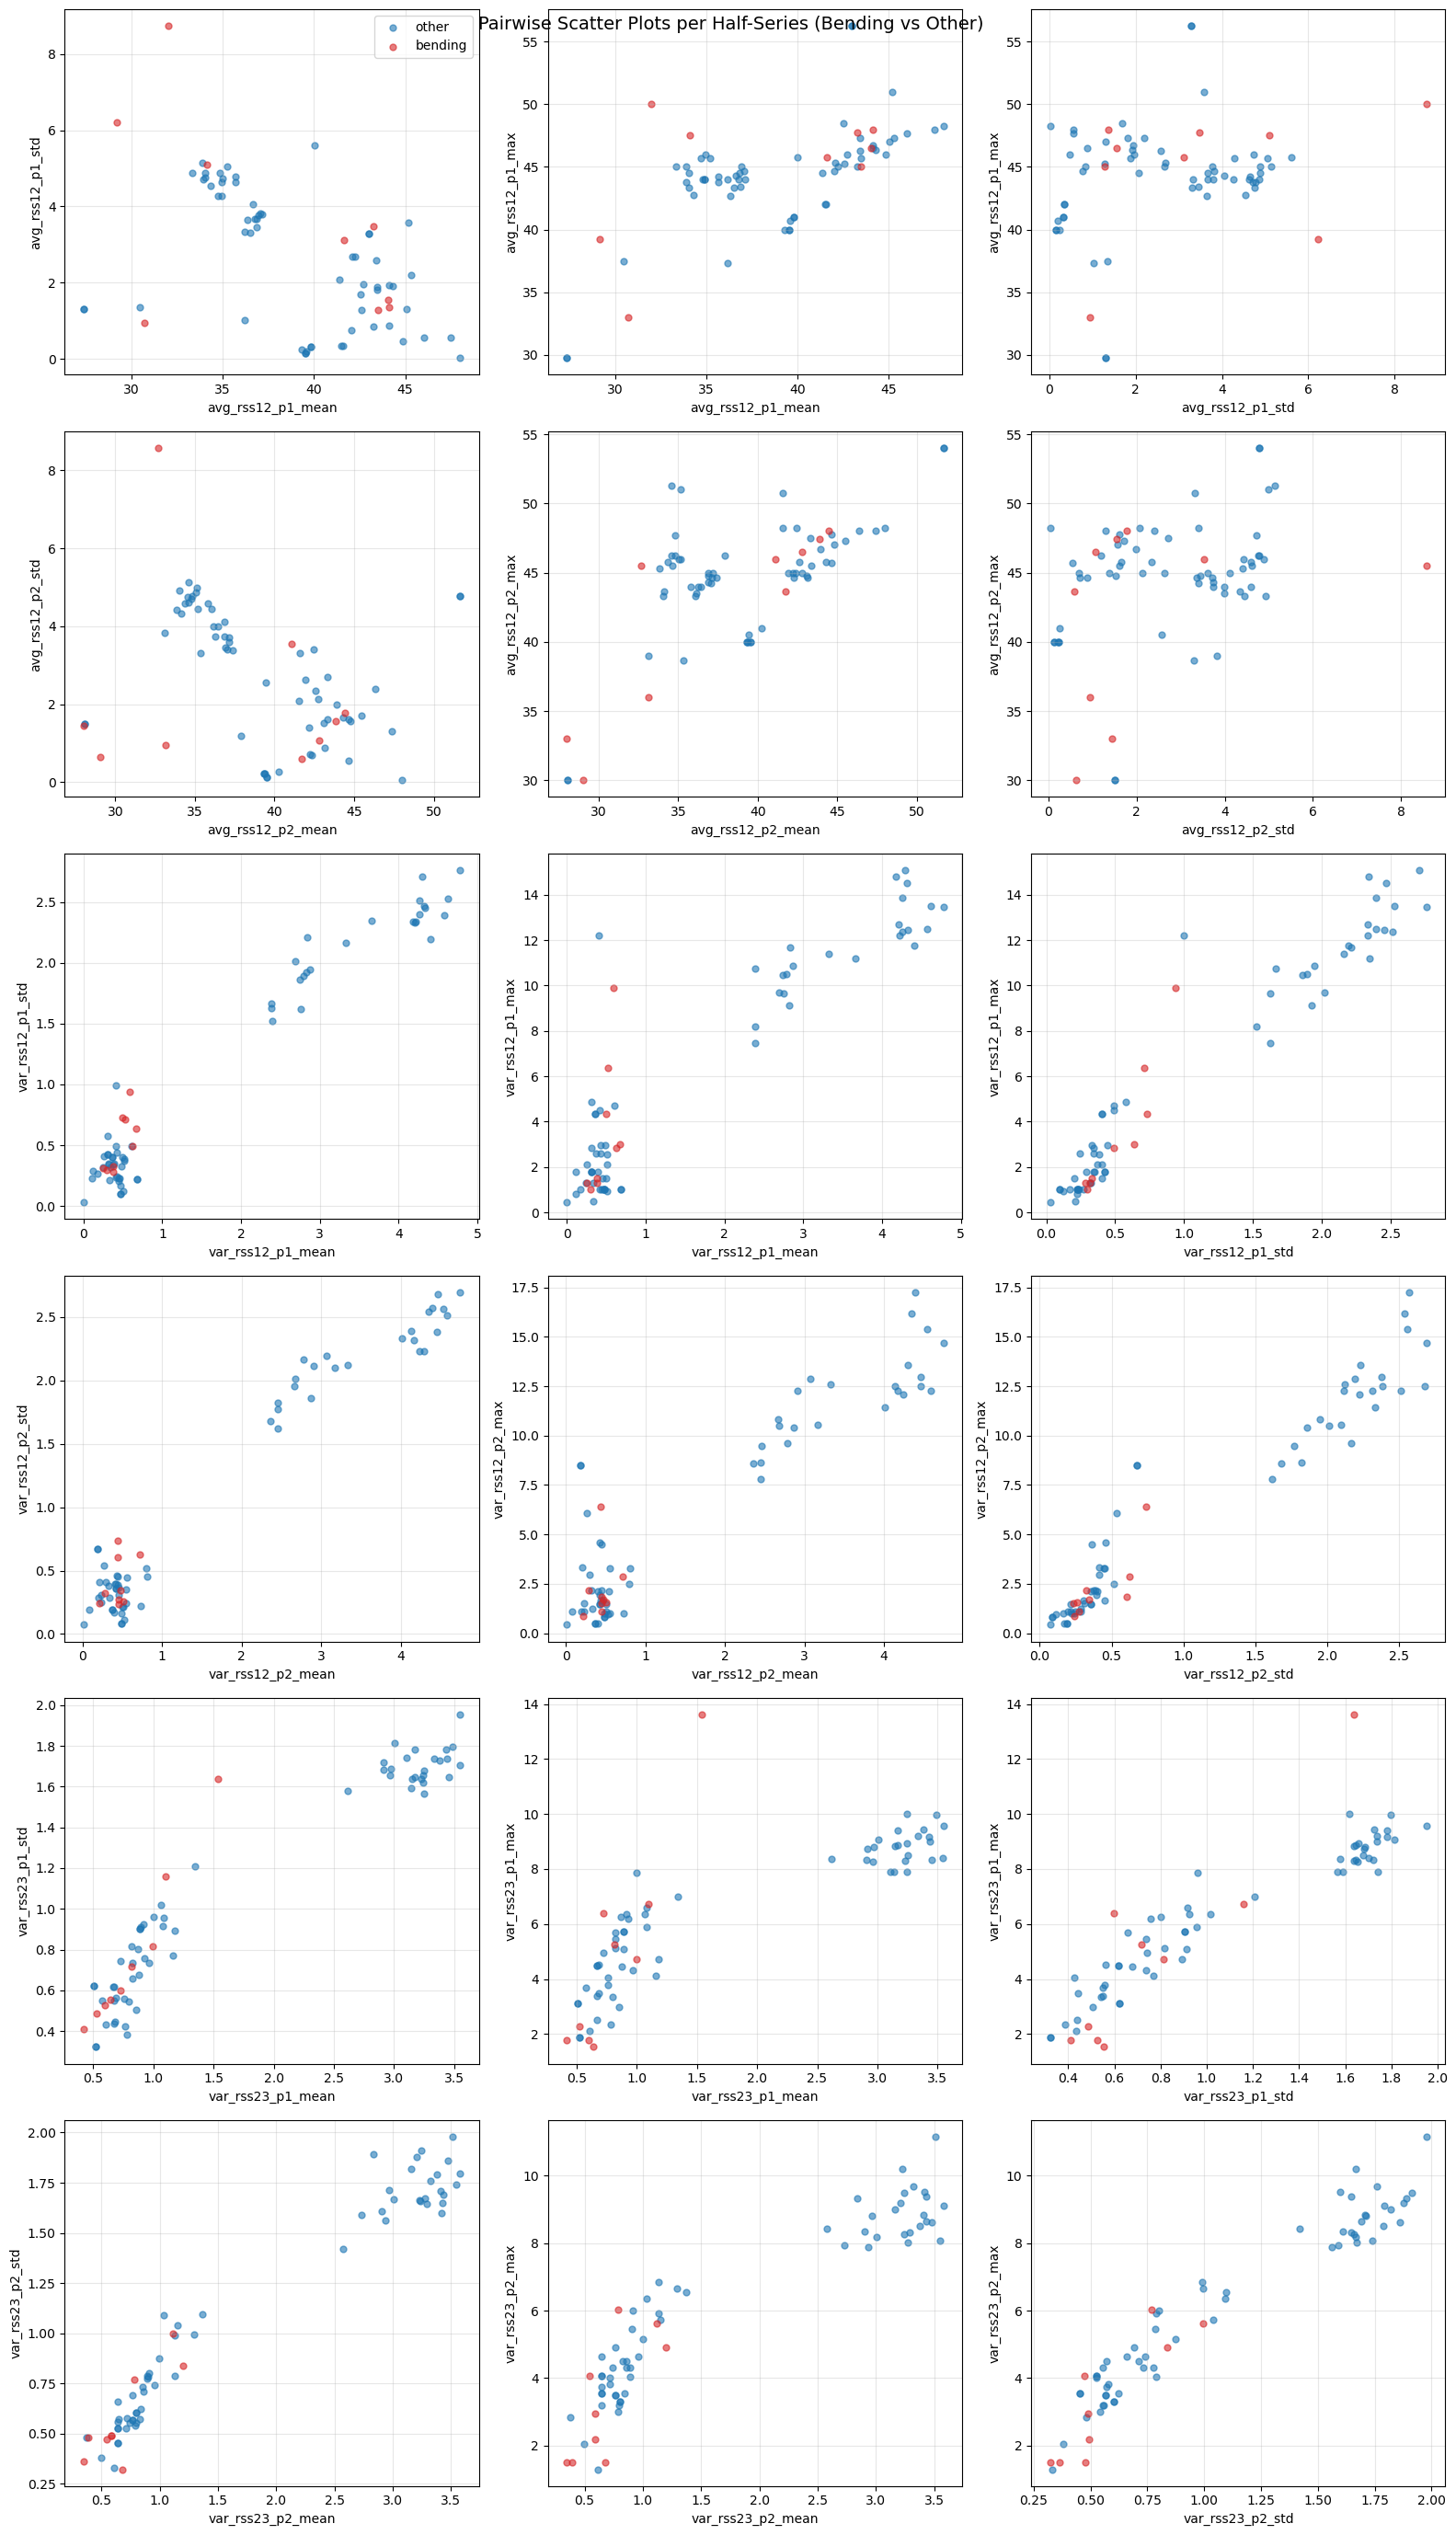

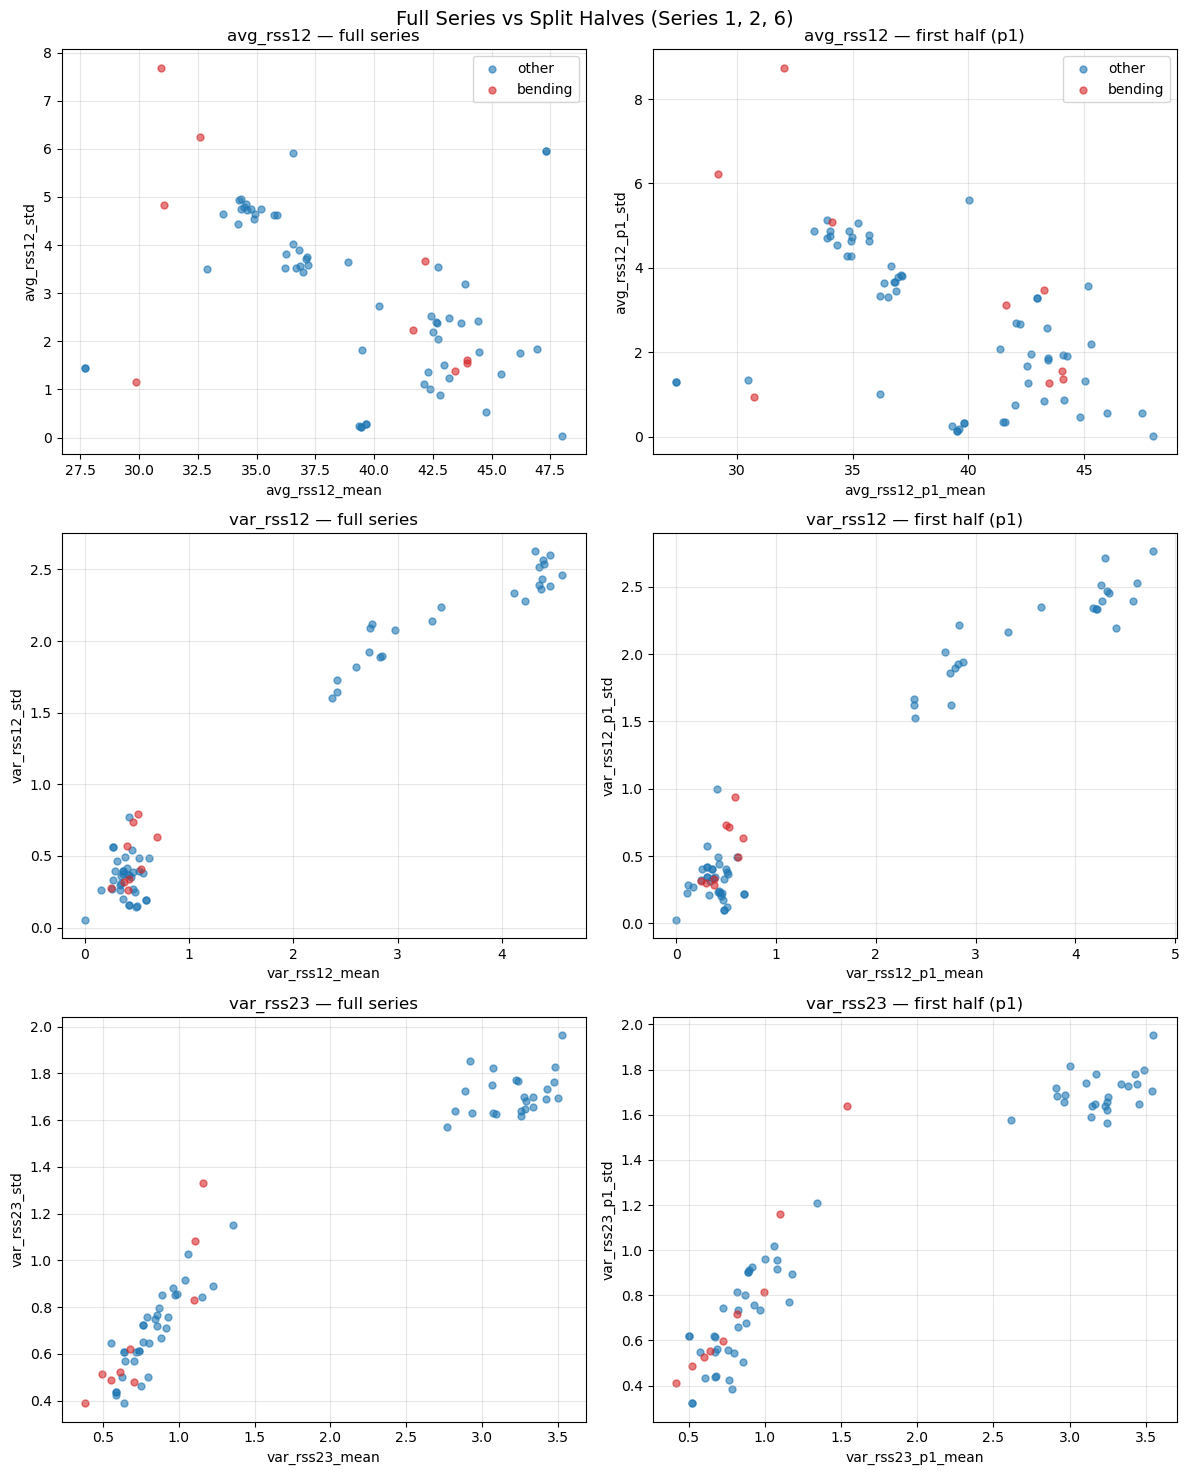

In [19]:
y_binary = np.array([
    "bending" if label.startswith("bending") else "other"
    for label in y_train
])

FEATURE_NAMES = ["min", "max", "mean", "median", "std", "q1", "q3"]

def extract_features(series):
    return [
        np.min(series), np.max(series), np.mean(series),
        np.median(series), np.std(series, ddof=1),
        np.percentile(series, 25), np.percentile(series, 75),
    ]

def split_instance(df, series_names):
    """
    Split each of the six series in df into two halves (240 + 240)
    and return a dictionary {series_name_part: 1D array}.
    """
    halves = {}
    for col in series_names:
        values = df[col].values
        half = len(values) // 2
        halves[f"{col}_p1"] = values[:half]      # first half
        halves[f"{col}_p2"] = values[half:]      # second half
    return halves


SPLIT_SERIES = [
    "avg_rss12_p1", "avg_rss12_p2",
    "var_rss12_p1", "var_rss12_p2",
    "var_rss23_p1", "var_rss23_p2",
]
SELECTED_FEATS = ["mean", "std", "max"]

split_cols = [f"{s}_{f}" for s in SPLIT_SERIES for f in SELECTED_FEATS]

X_train_split = []
for label, _, df in train_instances:
    halves = split_instance(df, ["avg_rss12", "var_rss12", "var_rss23"])
    row = []
    for s in SPLIT_SERIES:
        row.extend([dict(zip(FEATURE_NAMES,
                             extract_features(halves[s])))[f]
                    for f in SELECTED_FEATS])
    X_train_split.append(row)

X_train_split = np.array(X_train_split)

print("Split training matrix:", X_train_split.shape)   # (69, 18)


n = X_train_split.shape[1]
colors = {"other": "tab:blue", "bending": "tab:red"}

fig, axes = plt.subplots(n, n, figsize=(28, 28))

for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        if i == j:
            for label in ["other", "bending"]:
                mask = y_binary == label
                ax.hist(X_train_split[mask, i], bins=12,
                        alpha=0.5, color=colors[label], label=label)
        else:
            for label in ["other", "bending"]:
                mask = y_binary == label
                ax.scatter(X_train_split[mask, j],
                           X_train_split[mask, i],
                           c=colors[label], alpha=0.5, s=15)
        if i == n - 1:
            ax.set_xlabel(split_cols[j], fontsize=6, rotation=45)
        if j == 0:
            ax.set_ylabel(split_cols[i], fontsize=6)

axes[0, 0].legend(loc="upper right")
plt.suptitle("Scatter Plot Matrix: 18 Features from Halves of "
             "Series 1, 2, 6 (Bending vs Other)", fontsize=16)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(6, 3, figsize=(16, 28))

feature_pairs = [("mean", "std"), ("mean", "max"), ("std", "max")]

for row, series in enumerate(SPLIT_SERIES):
    for col, (f1, f2) in enumerate(feature_pairs):
        ax = axes[row, col]
        idx1 = split_cols.index(f"{series}_{f1}")
        idx2 = split_cols.index(f"{series}_{f2}")

        for label in ["other", "bending"]:
            mask = y_binary == label
            ax.scatter(X_train_split[mask, idx1],
                       X_train_split[mask, idx2],
                       c=colors[label], alpha=0.6, s=25, label=label)

        ax.set_xlabel(f"{series}_{f1}")
        ax.set_ylabel(f"{series}_{f2}")
        ax.grid(True, alpha=0.3)
        if row == 0 and col == 0:
            ax.legend()

plt.suptitle("Pairwise Scatter Plots per Half-Series "
             "(Bending vs Other)", fontsize=14)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(3, 2, figsize=(12, 15))

for row, series in enumerate(["avg_rss12", "var_rss12", "var_rss23"]):
    # Full series
    ax = axes[row, 0]
    idx_mean = feature_col_names.index(f"{series}_mean")
    idx_std = feature_col_names.index(f"{series}_std")
    for label in ["other", "bending"]:
        mask = y_binary == label
        ax.scatter(X_train[mask, idx_mean],
                   X_train[mask, idx_std],
                   c=colors[label], alpha=0.6, s=25, label=label)
    ax.set_title(f"{series} — full series")
    ax.set_xlabel(f"{series}_mean"); ax.set_ylabel(f"{series}_std")
    ax.grid(True, alpha=0.3)
    if row == 0:
        ax.legend()

    ax = axes[row, 1]
    idx_mean = split_cols.index(f"{series}_p1_mean")
    idx_std = split_cols.index(f"{series}_p1_std")
    for label in ["other", "bending"]:
        mask = y_binary == label
        ax.scatter(X_train_split[mask, idx_mean],
                   X_train_split[mask, idx_std],
                   c=colors[label], alpha=0.6, s=25, label=label)
    ax.set_title(f"{series} — first half (p1)")
    ax.set_xlabel(f"{series}_p1_mean"); ax.set_ylabel(f"{series}_p1_std")
    ax.grid(True, alpha=0.3)
    if row == 0:
        ax.legend()

plt.suptitle("Full Series vs Split Halves (Series 1, 2, 6)",
             fontsize=14)
plt.tight_layout()
plt.show()

After splitting each time series into two approximately equal halves, the scatter plots show some changes in feature values and the spread of the points. However, the overall patterns remain broadly similar, and bending and other activities overlap in several feature combinations both before and after splitting. There is no consistent, substantial improvement in visual class separation across the selected plots.

Features extracted from the first and second halves can differ because the signals vary over time. Splitting therefore preserves some temporal information that is lost when a single summary is calculated over the full series. However, each feature is now calculated from 240 observations instead of 480, which may make its estimate less stable.

Importantly, splitting does not change the number of training instances: it remains 69. It increases the number of time series per instance from 6 to 12. For the plots using mean, standard deviation, and maximum from time series 1, 2, and 6, the number of features increases from 9 to 18.

Overall, splitting changes the feature representation, but these scatter plots alone do not establish whether it improves classification accuracy. That question is evaluated using cross-validation in the following part.

#### iii. Time Series Segments

In [81]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings("ignore")

SERIES_NAMES = ["avg_rss12", "var_rss12", "avg_rss13",
                "var_rss13", "avg_rss23", "var_rss23"]
FEATURE_NAMES = ["min", "max", "mean", "median", "std", "q1", "q3"]

def extract_features(series):
    return [
        np.min(series), np.max(series), np.mean(series),
        np.median(series), np.std(series, ddof=1),
        np.percentile(series, 25), np.percentile(series, 75),
    ]

def extract_features_for_l(df, l):
    vec = []
    for col in SERIES_NAMES:
        values = df[col].values
        segments = np.array_split(values, l)  
        for seg in segments:
            vec.extend(extract_features(seg))
    return vec

def make_binary_labels(labels):
    return np.array([1 if lab.startswith("bending") else 0 for lab in labels])

y_train_bin = make_binary_labels([lab for lab, _, _ in train_instances])
y_test_bin  = make_binary_labels([lab for lab, _, _ in test_instances])

l_values = list(range(1, 21))          
p_values = [1, 2, 3, 5, 10, 15, 20, 30, 40, 50]  

cv_results = []

for l in l_values:
    X_l = np.array([extract_features_for_l(df, l)
                    for _, _, df in train_instances])
    n_features_total = X_l.shape[1]

    p_list_l = [p for p in p_values if p <= n_features_total]

    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    fold_accuracies = {p: [] for p in p_list_l}

    for train_idx, val_idx in skf.split(X_l, y_train_bin):
        X_tr, X_val = X_l[train_idx], X_l[val_idx]
        y_tr, y_val = y_train_bin[train_idx], y_train_bin[val_idx]

        for p in p_list_l:
            base_clf = LogisticRegression(
                penalty=None,
                max_iter=1000,
                random_state=42
            )

            rfe = RFE(
                estimator=base_clf,
                n_features_to_select=p,
                step=0.1
            )

            rfe.fit(X_tr, y_tr)

            y_pred = rfe.predict(X_val)

            fold_accuracies[p].append(
                accuracy_score(y_val, y_pred)
            )

    for p in p_list_l:
        mean_acc = np.mean(fold_accuracies[p])
        cv_results.append({"l": l, "p": p, "cv_accuracy": mean_acc})

cv_df = pd.DataFrame(cv_results)
best_row = cv_df.loc[cv_df["cv_accuracy"].idxmax()]
best_l = int(best_row["l"])
best_p = int(best_row["p"])

print("=" * 60)
print("Best (l, p) by 5-fold CV:")
print(f"  l = {best_l}, p = {best_p}, CV accuracy = {best_row['cv_accuracy']:.4f}")
print("=" * 60)

X_train_best = np.array([extract_features_for_l(df, best_l)
                         for _, _, df in train_instances])
X_test_best  = np.array([extract_features_for_l(df, best_l)
                         for _, _, df in test_instances])

base_clf = LogisticRegression(penalty=None, max_iter=1000, random_state=42)
rfe_best = RFE(estimator=base_clf, n_features_to_select=best_p, step=0.1)
rfe_best.fit(X_train_best, y_train_bin)

X_train_sel = rfe_best.transform(X_train_best)
X_test_sel  = rfe_best.transform(X_test_best)

final_clf = LogisticRegression(penalty=None, max_iter=1000, random_state=42)
final_clf.fit(X_train_sel, y_train_bin)
y_pred_test = final_clf.predict(X_test_sel)

test_acc = accuracy_score(y_test_bin, y_pred_test)
print(f"Final test accuracy with l={best_l}, p={best_p}: {test_acc:.4f}")

print("\nTop 10 (l, p) combinations by CV accuracy:")
print(cv_df.sort_values("cv_accuracy", ascending=False).head(10).to_string(index=False))

Best (l, p) by 5-fold CV:
  l = 1, p = 10, CV accuracy = 1.0000
Final test accuracy with l=1, p=10: 1.0000

Top 10 (l, p) combinations by CV accuracy:
 l  p  cv_accuracy
 1 10     1.000000
19 30     0.985714
14  5     0.985714
18 10     0.985714
15 40     0.985714
18 15     0.985714
19 40     0.985714
12 15     0.985714
19  5     0.985714
 5 10     0.985714


For each l ∈ {1, 2, ..., 20}, each of the six time series within an instance was divided into l approximately equal-length segments. Seven time-domain features—minimum, maximum, mean, median, standard deviation, first quartile, and third quartile—were extracted from each segment, producing 42l candidate features per instance. The number of training instances remained 69.

Logistic regression without regularization was combined with Recursive Feature Elimination (RFE). Stratified 5-fold cross-validation was used to select the best combination of l and the number of retained features p. Stratification approximately preserves class proportions across folds, which is useful because the training set contains only 9 bending instances and 60 other instances.

For each candidate pair (l, p), RFE was fitted independently on each fold's training portion to retain p features. The fitted selector and classifier were then applied to the validation portion. Performing feature selection on the entire training set before cross-validation would be incorrect because the validation labels would influence feature selection, potentially producing an overly optimistic accuracy estimate.

The best combination among the evaluated candidates was l = 1 and p = 10, with a mean 5-fold cross-validation accuracy of 1.0000. RFE and logistic regression were then fitted on all 69 training instances using these settings. The final classifier correctly classified all 19 test instances, giving a test accuracy of 1.0000.

These results show that features extracted from the full-length time series were sufficient for accurate classification on this split. However, the small test set, containing only 4 bending instances, limits the strength of conclusions about performance on new data.

#### iv. Confusion Matrix

Confusion Matrix (Training Set)
[[60  0]
 [ 0  9]]

Classification Report:
              precision    recall  f1-score   support

       other       1.00      1.00      1.00        60
     bending       1.00      1.00      1.00         9

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69


Training AUC: 1.0000


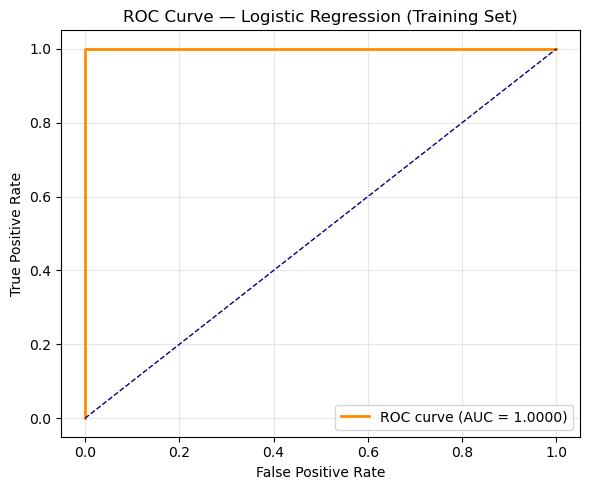


Logistic Regression Coefficients (sklearn)
         feature  coefficient
  avg_rss12_mean    -0.974821
    avg_rss12_q3    -1.333445
avg_rss13_median    -0.487110
    avg_rss13_q3    -0.442709
   avg_rss23_min     1.344949
   avg_rss23_max     1.742310
  avg_rss23_mean     1.026617
    avg_rss23_q1     1.114413
    avg_rss23_q3     0.758432
   var_rss23_max    -1.357844

Intercept: -0.0502

Logistic Regression with p-values (statsmodels)
         feature  coefficient  standard_error  p_value
           const    -0.731413    1.481758e+08 1.000000
  avg_rss12_mean    -0.963878    1.307302e+07 1.000000
    avg_rss12_q3    -3.947616    7.824239e+06 1.000000
avg_rss13_median    -1.540288    1.503276e+07 1.000000
    avg_rss13_q3    -0.494332    1.533442e+07 1.000000
   avg_rss23_min     1.132684    1.103762e+07 1.000000
   avg_rss23_max     5.717170    1.600107e+07 1.000000
  avg_rss23_mean     2.294033    1.952250e+08 1.000000
    avg_rss23_q1     2.426605    1.021293e+08 1.000000
    avg

In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_curve, auc, classification_report
import statsmodels.api as sm

y_train_pred = final_clf.predict(X_train_sel)

cm = confusion_matrix(y_train_bin, y_train_pred)
print("=" * 60)
print("Confusion Matrix (Training Set)")
print("=" * 60)
print(cm)
print("\nClassification Report:")
print(classification_report(y_train_bin, y_train_pred,
                            target_names=["other", "bending"]))

y_train_prob = final_clf.predict_proba(X_train_sel)[:, 1]

fpr, tpr, thresholds = roc_curve(y_train_bin, y_train_prob)
roc_auc = auc(fpr, tpr)

print(f"\nTraining AUC: {roc_auc:.4f}")

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="darkorange", lw=2,
         label=f"ROC curve (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], color="navy", lw=1, linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Logistic Regression (Training Set)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("Logistic Regression Coefficients (sklearn)")
print("=" * 60)

selected_feature_names = [
    feature_col_names[i] for i in range(len(feature_col_names))
    if rfe_best.support_[i]
]

coef_df = pd.DataFrame({
    "feature": selected_feature_names,
    "coefficient": final_clf.coef_[0],
})
print(coef_df.to_string(index=False))
print(f"\nIntercept: {final_clf.intercept_[0]:.4f}")

# ---------- 4. Coefficients and p-values from statsmodels ----------
import warnings

print("\n" + "=" * 60)
print("Logistic Regression with p-values (statsmodels)")
print("=" * 60)

# Add an intercept column.
X_train_const = sm.add_constant(X_train_sel)

try:
    # Show relevant warnings even if earlier cells suppressed them.
    with warnings.catch_warnings():
        warnings.simplefilter("default")

        logit_model = sm.Logit(y_train_bin, X_train_const)

        result = logit_model.fit(
            disp=0,
            method="bfgs",
            maxiter=1000
        )

    stat_df = pd.DataFrame({
        "feature": ["const"] + selected_feature_names,
        "coefficient": np.asarray(result.params),
        "standard_error": np.asarray(result.bse),
        "p_value": np.asarray(result.pvalues),
    })

    print(stat_df.to_string(index=False))

    print(
        "\nOptimizer reports convergence:",
        result.mle_retvals.get("converged", "Unknown")
    )

    print(
        "All p-values are finite:",
        np.isfinite(np.asarray(result.pvalues)).all()
    )

except Exception as e:
    print(f"statsmodels raised {type(e).__name__}: {e}")

**Confusion Matrix (Training Set).**

|                | Predicted other | Predicted bending |
|----------------|-----------------|-------------------|
| Actual other   | 60              | 0                 |
| Actual bending | 0               | 9                 |

All 69 training instances were classified correctly, giving a training accuracy of 1.0000. The classification report shows precision, recall, and F1-score of 1.00 for both classes.

**ROC Curve and AUC.** The ROC curve was constructed from the predicted probabilities of the bending class. The curve rises vertically from (0, 0) to (0, 1) and then extends horizontally to (1, 1), giving an AUC of 1.0000. This indicates perfect discrimination on the training set.

**Logistic Regression Coefficients.** The sklearn model has the form log(p/(1−p)) = β₀ + Σ βᵢxᵢ, where p is the probability of bending. Among the 10 selected features, the `avg_rss23_*` features (min, max, mean, q1, q3) have positive coefficients between approximately +0.76 and +1.74. Holding the other selected features fixed, higher values of these features increase the fitted log-odds of bending. The `avg_rss12_mean`, `avg_rss12_q3`, `avg_rss13_median`, `avg_rss13_q3`, and `var_rss23_max` features have negative coefficients. The intercept is approximately −0.0502.

**p-values.** The separate statsmodels fit reported convergence and returned finite p-values. However, its standard errors were extremely large, approximately 10⁶–10⁸, and the p-values were approximately 1. The selected features perfectly separate the training classes. Under complete separation, unpenalized logistic regression has no finite maximum-likelihood coefficient estimate, making the usual Wald standard errors and p-values unreliable. Therefore, these large p-values should not be interpreted as evidence that the features have no predictive value. The reported convergence indicates that the optimizer met its numerical stopping criterion; it does not establish that the coefficient estimates or statistical inference are valid.

**Interpretation.** The selected features separate bending from other activities perfectly on this training set. However, the training set contains only 69 instances, including 9 bending instances, and the test set contains only 19 instances. Perfect training accuracy and AUC therefore provide limited evidence about performance on new data. The finite coefficients returned by sklearn and statsmodels should be treated as numerical approximations rather than stable maximum-likelihood estimates.

#### v. Test Classifier

In [91]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


X_test_best = np.array([
    extract_features_for_l(df, best_l)
    for _, _, df in test_instances
])

print("Test feature matrix (before RFE):", X_test_best.shape)

X_test_sel = rfe_best.transform(X_test_best)
print("Test feature matrix (after RFE):", X_test_sel.shape)

y_test_pred = final_clf.predict(X_test_sel)
y_test_prob = final_clf.predict_proba(X_test_sel)[:, 1]

test_acc = accuracy_score(y_test_bin, y_test_pred)

print("\n" + "=" * 60)
print("2(a)(v) Evaluation on Test Set")
print("=" * 60)
print(f"Test accuracy: {test_acc:.4f}")

print("\nConfusion Matrix (Test Set):")
print(confusion_matrix(y_test_bin, y_test_pred))

print("\nClassification Report (Test Set):")
print(classification_report(y_test_bin, y_test_pred,
                            target_names=["other", "bending"]))

print("\n" + "=" * 60)
print("Comparison: CV accuracy vs Test accuracy")
print("=" * 60)
cv_acc = float(best_row["cv_accuracy"])

print(
    f"5-fold CV accuracy (l={best_l}, p={best_p}): "
    f"{cv_acc:.4f}"
)

print(
    f"Test accuracy (l={best_l}, p={best_p}): "
    f"{test_acc:.4f}"
)

print(f"Difference: {test_acc - cv_acc:+.4f}")

Test feature matrix (before RFE): (19, 42)
Test feature matrix (after RFE): (19, 10)

2(a)(v) Evaluation on Test Set
Test accuracy: 1.0000

Confusion Matrix (Test Set):
[[15  0]
 [ 0  4]]

Classification Report (Test Set):
              precision    recall  f1-score   support

       other       1.00      1.00      1.00        15
     bending       1.00      1.00      1.00         4

    accuracy                           1.00        19
   macro avg       1.00      1.00      1.00        19
weighted avg       1.00      1.00      1.00        19


Comparison: CV accuracy vs Test accuracy
5-fold CV accuracy (l=1, p=10): 1.0000
Test accuracy (l=1, p=10): 1.0000
Difference: +0.0000


**Test Set Preparation.** The selected model from 2(a)(iii) used l = 1 and p = 10. Therefore, each test time series was kept at its full length of 480 observations. Seven time-domain features (min, max, mean, median, std, q1, q3) were extracted from each of the six series, producing 42 features per test instance.

The RFE selector fitted on the training set was applied to the test set using `transform`, retaining the same 10 features. The trained logistic regression classifier was then used to predict the test labels.

**Confusion Matrix (Test Set).**

|                | Predicted other | Predicted bending |
|----------------|-----------------|-------------------|
| Actual other   | 15              | 0                 |
| Actual bending | 0               | 4                 |

All 19 test instances were classified correctly, giving a test accuracy of 1.0000. Precision, recall, and F1-score were all 1.00 for both classes.

**Comparison with CV Accuracy.**

| Metric | Value |
|--------|-------|
| 5-fold CV accuracy (l = 1, p = 10) | 1.0000 |
| Test accuracy (l = 1, p = 10) | 1.0000 |
| Difference | 0.0000 |

The test accuracy matches the cross-validation accuracy on this split.

**Interpretation.** These results show strong classification performance on the available data. However, the test set contains only 19 instances, including 4 bending instances. A single test error would reduce accuracy to approximately 0.9474. Therefore, the perfect scores do not establish that the model is free from overfitting or will perform perfectly on future observations.

#### vi. Separation

**Separation.** Yes. The bending and other classes appear to be completely linearly separable in the selected 10-feature space, creating instability in the estimation of unpenalized logistic regression parameters.

**Evidence.**

- The training confusion matrix is [[60, 0], [0, 9]], indicating that the fitted linear decision boundary correctly classifies all 69 training instances.
- Training accuracy and AUC are both 1.0000.
- The statsmodels fit produces extremely large standard errors, approximately 10⁶–10⁸, and Wald p-values close to 1.
- sklearn and statsmodels return different finite coefficient estimates for the same selected features. These differences are consistent with unstable estimation under separation.

**Why Separation Causes Instability.** When a linear boundary completely separates the classes, scaling the coefficients along a separating direction makes the fitted probabilities approach 1 for bending and 0 for other activities. The log-likelihood continues to improve toward its supremum without attaining a finite maximum. Consequently, the ordinary unpenalized maximum-likelihood coefficient estimate does not exist as a finite vector, and the usual Wald standard errors and p-values are unreliable.

**Convergence and Finite Coefficients.** Although statsmodels reports convergence, this indicates that the optimizer satisfied its numerical stopping criterion. It does not establish that a finite maximum-likelihood estimate exists. The finite coefficients returned by sklearn and statsmodels depend on numerical optimization and stopping criteria and should not be interpreted as stable parameter estimates.

**Implications.** The selected features provide excellent classification on the observed training data, but this does not imply reliable coefficient inference. Regularization can stabilize coefficient estimation, as explored in the following L1-penalized models. The p-values close to 1 should therefore not be interpreted as evidence that the selected features lack predictive value.

#### vii. Imbalance

Balanced training set: 18 instances (9 bending, 9 other)
Original intercept: -0.0643
Adjustment term: -1.8971
Adjusted intercept: -1.9615

Test accuracy after case-control sampling: 1.0000

Confusion Matrix (Test Set):
[[15  0]
 [ 0  4]]

Classification Report:
              precision    recall  f1-score   support

       other       1.00      1.00      1.00        15
     bending       1.00      1.00      1.00         4

    accuracy                           1.00        19
   macro avg       1.00      1.00      1.00        19
weighted avg       1.00      1.00      1.00        19



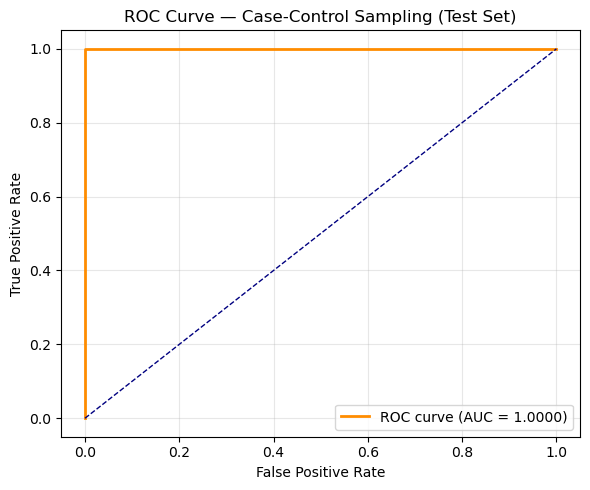


Test AUC: 1.0000


In [97]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_curve, auc, classification_report
from sklearn.utils import resample

idx_bending = np.where(y_train_bin == 1)[0]
idx_other   = np.where(y_train_bin == 0)[0]

n_bending = len(idx_bending)          
n_other   = len(idx_other)            

idx_other_sampled = resample(idx_other,
                             replace=False,
                             n_samples=n_bending,
                             random_state=42)

idx_balanced = np.concatenate([idx_bending, idx_other_sampled])

X_bal = X_train_sel[idx_balanced]
y_bal = y_train_bin[idx_balanced]

print(f"Balanced training set: {X_bal.shape[0]} instances "
      f"({n_bending} bending, {n_bending} other)")

clf_bal = LogisticRegression(penalty=None, max_iter=1000, random_state=42)
clf_bal.fit(X_bal, y_bal)

beta0_orig = clf_bal.intercept_[0]
print(f"Original intercept: {beta0_orig:.4f}")

pi1 = n_bending / len(y_train_bin)     
pi0 = n_other / len(y_train_bin)       
rho1 = 0.5
rho0 = 0.5

adjustment = np.log((pi1 / pi0) / (rho1 / rho0))
beta0_adj = beta0_orig + adjustment

print(f"Adjustment term: {adjustment:.4f}")
print(f"Adjusted intercept: {beta0_adj:.4f}")


clf_bal.intercept_ = np.array([beta0_adj])

y_pred = clf_bal.predict(X_test_sel)
y_prob = clf_bal.predict_proba(X_test_sel)[:, 1]

acc = (y_pred == y_test_bin).mean()
print(f"\nTest accuracy after case-control sampling: {acc:.4f}")

print("\nConfusion Matrix (Test Set):")
print(confusion_matrix(y_test_bin, y_pred))

print("\nClassification Report:")
print(classification_report(y_test_bin, y_pred,
                            target_names=["other", "bending"]))

fpr, tpr, _ = roc_curve(y_test_bin, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="darkorange", lw=2,
         label=f"ROC curve (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], color="navy", lw=1, linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Case-Control Sampling (Test Set)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nTest AUC: {roc_auc:.4f}")

**Class Imbalance.** The training set contains 9 bending instances and 60 other instances, corresponding to an approximately 1:6.7 ratio. Therefore, the classes are imbalanced.

**Case-Control Sampling.** All 9 bending instances were retained, and 9 other instances were randomly sampled without replacement using `random_state=42`. An unpenalized logistic regression model was fitted to this balanced dataset of 18 instances using the previously selected 10 features.

**Intercept Adjustment.** The model fitted to the balanced sample had an intercept of approximately −0.0643. To account for the original training-set class proportions, the intercept was adjusted using:

β₀_adjusted = β₀_sample + log((π₁/π₀)/(ρ₁/ρ₀))

Here, π₁ = 9/69 and π₀ = 60/69 are the original training-set class proportions, while ρ₁ = ρ₀ = 0.5 are the balanced-sample proportions. The adjustment term is log(0.15) ≈ −1.8971, giving an adjusted intercept of approximately −1.9615. The slope coefficients were left unchanged.

**Confusion Matrix (Test Set).**

|                | Predicted other | Predicted bending |
|----------------|-----------------|-------------------|
| Actual other   | 15              | 0                 |
| Actual bending | 0               | 4                 |

All 19 test instances were classified correctly after the intercept adjustment. Test accuracy, precision, recall, and F1-score were all 1.00.

**ROC Curve and AUC.** The test ROC curve was constructed using the adjusted model’s predicted probabilities of bending. The test AUC was 1.0000, indicating perfect discrimination on this test set.

**Interpretation.** The intercept correction lowers the predicted probability of bending to account for its lower proportion in the original training set. Test classification accuracy remains 1.0000. However, this correction alone does not establish that the probabilities are well calibrated. The small balanced training sample and the separation identified earlier still limit the reliability of coefficient and probability estimates.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [104]:
import warnings
import sklearn
import numpy as np
import pandas as pd

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score

warnings.simplefilter("default", ConvergenceWarning)

l1_y_train = np.array([
    1 if label.startswith("bending") else 0
    for label, _, _ in train_instances
])

l1_l_values = list(range(1, 21))
l1_C_values = np.logspace(-3, 2, 20)

l1_outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

l1_inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

l1_lr_settings = {
    "solver": "liblinear",
    "max_iter": 5000,
    "random_state": 42
}

l1_sklearn_version = tuple(
    int(part) for part in sklearn.__version__.split(".")[:2]
)

if l1_sklearn_version >= (1, 8):
    l1_lr_settings["l1_ratio"] = 1.0
else:
    l1_lr_settings["penalty"] = "l1"

l1_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(**l1_lr_settings))
])

l1_cv_results = []

for l in l1_l_values:
    X_l = np.array([
        extract_features_for_l(df, l)
        for _, _, df in train_instances
    ])

    fold_accuracies = []

    for train_idx, val_idx in l1_outer_cv.split(X_l, l1_y_train):
        X_tr = X_l[train_idx]
        X_val = X_l[val_idx]

        y_tr = l1_y_train[train_idx]
        y_val = l1_y_train[val_idx]

        grid = GridSearchCV(
            estimator=l1_pipeline,
            param_grid={"clf__C": l1_C_values},
            cv=l1_inner_cv,
            scoring="accuracy",
            refit=True
        )

        grid.fit(X_tr, y_tr)

        y_pred = grid.predict(X_val)
        fold_accuracies.append(
            accuracy_score(y_val, y_pred)
        )

    mean_accuracy = np.mean(fold_accuracies)

    l1_cv_results.append({
        "l": l,
        "cv_accuracy": mean_accuracy
    })

    print(
        f"l = {l:2d} | features = {X_l.shape[1]:3d} | "
        f"CV accuracy = {mean_accuracy:.4f}"
    )

l1_cv_df = pd.DataFrame(l1_cv_results)
l1_best_row = l1_cv_df.loc[l1_cv_df["cv_accuracy"].idxmax()]

l1_best_l = int(l1_best_row["l"])
l1_best_cv_accuracy = float(l1_best_row["cv_accuracy"])

print("\n" + "=" * 60)
print(
    f"Best l = {l1_best_l}, "
    f"CV accuracy = {l1_best_cv_accuracy:.4f}"
)

l1_X_train_best = np.array([
    extract_features_for_l(df, l1_best_l)
    for _, _, df in train_instances
])

l1_final_grid = GridSearchCV(
    estimator=l1_pipeline,
    param_grid={"clf__C": l1_C_values},
    cv=l1_inner_cv,
    scoring="accuracy",
    refit=True
)

l1_final_grid.fit(l1_X_train_best, l1_y_train)

l1_final_model = l1_final_grid.best_estimator_
l1_best_C = l1_final_grid.best_params_["clf__C"]

l1_coefficients = l1_final_model.named_steps["clf"].coef_[0]
l1_n_nonzero = np.sum(np.abs(l1_coefficients) > 1e-6)

l1_X_test_best = np.array([
    extract_features_for_l(df, l1_best_l)
    for _, _, df in test_instances
])

l1_y_test = np.array([
    1 if label.startswith("bending") else 0
    for label, _, _ in test_instances
])

l1_y_pred_test = l1_final_model.predict(l1_X_test_best)
l1_test_accuracy = accuracy_score(l1_y_test, l1_y_pred_test)

print(f"Best C: {l1_best_C:.6g}")
print(
    f"Non-zero coefficients: "
    f"{l1_n_nonzero} / {len(l1_coefficients)}"
)
print(f"Test accuracy: {l1_test_accuracy:.4f}")
print(f"Test error: {1 - l1_test_accuracy:.4f}")
print("=" * 60)

l =  1 | features =  42 | CV accuracy = 0.9275
l =  2 | features =  84 | CV accuracy = 0.9132
l =  3 | features = 126 | CV accuracy = 0.9571
l =  4 | features = 168 | CV accuracy = 0.9132
l =  5 | features = 210 | CV accuracy = 0.9275
l =  6 | features = 252 | CV accuracy = 0.9429
l =  7 | features = 294 | CV accuracy = 0.9560
l =  8 | features = 336 | CV accuracy = 0.9275
l =  9 | features = 378 | CV accuracy = 0.9418
l = 10 | features = 420 | CV accuracy = 0.9429
l = 11 | features = 462 | CV accuracy = 0.9571
l = 12 | features = 504 | CV accuracy = 0.9571
l = 13 | features = 546 | CV accuracy = 0.9429
l = 14 | features = 588 | CV accuracy = 0.9418
l = 15 | features = 630 | CV accuracy = 0.9132
l = 16 | features = 672 | CV accuracy = 0.9286
l = 17 | features = 714 | CV accuracy = 0.9132
l = 18 | features = 756 | CV accuracy = 0.9571
l = 19 | features = 798 | CV accuracy = 0.9571
l = 20 | features = 840 | CV accuracy = 0.9714

Best l = 20, CV accuracy = 0.9714
Best C: 29.7635
Non-zero 

**Method.** L1-penalized logistic regression with the `liblinear` solver was used for binary classification of bending versus other activities. For each l ∈ {1, 2, ..., 20}, each of the six time series was divided into l approximately equal-length segments, and seven time-domain features were extracted from each segment.

A pipeline combined `StandardScaler` with logistic regression. For each candidate l, outer stratified 5-fold cross-validation evaluated the model-building procedure, while inner stratified 5-fold cross-validation selected C from 20 logarithmically spaced values between 0.001 and 100. Standardization was fitted within each training fold to prevent preprocessing leakage.

The l with the highest mean outer CV accuracy was selected. At this l, C was selected again using stratified 5-fold CV on the full training set, and the final pipeline was fitted before evaluating the test set.

**Results.**

| Metric | Value |
|--------|-------|
| Best l | 20 |
| Best C | 29.7635 |
| CV accuracy used to select l | 0.9714 |
| Non-zero coefficients, using \|β\| > 10⁻⁶ | 27 / 840 |
| Test accuracy | 0.9474 |
| Test error | 0.0526 |

**Feature Selection.** With l = 20, each original 480-observation time series was divided into 20 segments of 24 observations each. This produced 6 × 20 × 7 = 840 candidate features per instance. The L1 penalty produced a sparse model with 27 coefficients exceeding the numerical threshold of 10⁻⁶ in absolute value.

**Interpretation.** Among the evaluated segmentation choices, l = 20 achieved the highest mean outer CV accuracy. The final classifier correctly classified 18 of the 19 test instances. The CV score was used to select l and should not be treated as an unbiased estimate of the selected model’s future accuracy. The small test set also limits conclusions about generalization.

#### ii. Comparison

**Performance.**

| Method | Best parameters | Reported CV accuracy | Test accuracy | Features retained |
|--------|-----------------|----------------------|---------------|-------------------|
| RFE-based logistic regression | l = 1, p = 10 | 1.0000 | 1.0000 | 10 |
| L1-penalized logistic regression | l = 20, C = 29.7635 | 0.9714 | 0.9474 | 27 |

The RFE-based model correctly classified all 19 test instances, while the L1-penalized model correctly classified 18 of 19. Thus, RFE achieved higher observed test accuracy and retained fewer features on this split.

However, the difference corresponds to only one test instance. The small test set does not provide strong evidence that RFE will consistently outperform L1 on new data. The reported CV scores also come from different tuning procedures: RFE evaluated candidate (l, p) pairs directly using 5-fold CV, whereas the L1 procedure used inner CV to select C before evaluating each outer validation fold.

**Feature Selection Method.** The RFE alternative permitted in 2(a)(iii) was used instead of p-value-based pruning. RFE recursively removes features according to the fitted model’s coefficient magnitudes. L1 regularization performs embedded feature selection by shrinking some coefficients to zero. Neither of these implementations requires p-values.

Conventional p-value-based pruning would be problematic here because complete separation makes the ordinary logistic regression Wald p-values unreliable, as discussed in 2(a)(iv).

**Ease of Implementation.** L1 regularization provides a simpler mechanism for feature selection: tuning C controls regularization, and zero coefficients identify excluded features. RFE requires repeated model fitting and feature elimination for each candidate number of retained features p. Both methods still require cross-validation to select their tuning parameters and the segmentation level l.

For this experiment, RFE produced the better observed test result. L1 offered a simpler embedded feature-selection mechanism and regularized coefficient estimation, but it did not achieve higher test accuracy.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

Training instances per class:
bending1     5
bending2     4
cycling     12
lying       12
sitting     12
standing    12
walking     12

Note: bending2 has only 4 training instances, so one outer validation fold will contain no bending2 instances.
l =  1 | features =  42 | CV accuracy = 0.8560
l =  2 | features =  84 | CV accuracy = 0.9143
l =  3 | features = 126 | CV accuracy = 0.8286
l =  4 | features = 168 | CV accuracy = 0.8418
l =  5 | features = 210 | CV accuracy = 0.8418
l =  6 | features = 252 | CV accuracy = 0.8418
l =  7 | features = 294 | CV accuracy = 0.8418
l =  8 | features = 336 | CV accuracy = 0.8407
l =  9 | features = 378 | CV accuracy = 0.8418
l = 10 | features = 420 | CV accuracy = 0.7989
l = 11 | features = 462 | CV accuracy = 0.7264
l = 12 | features = 504 | CV accuracy = 0.7967
l = 13 | features = 546 | CV accuracy = 0.7835
l = 14 | features = 588 | CV accuracy = 0.7681
l = 15 | features = 630 | CV accuracy = 0.7978
l = 16 | features = 672 | CV accuracy = 0.7538
l

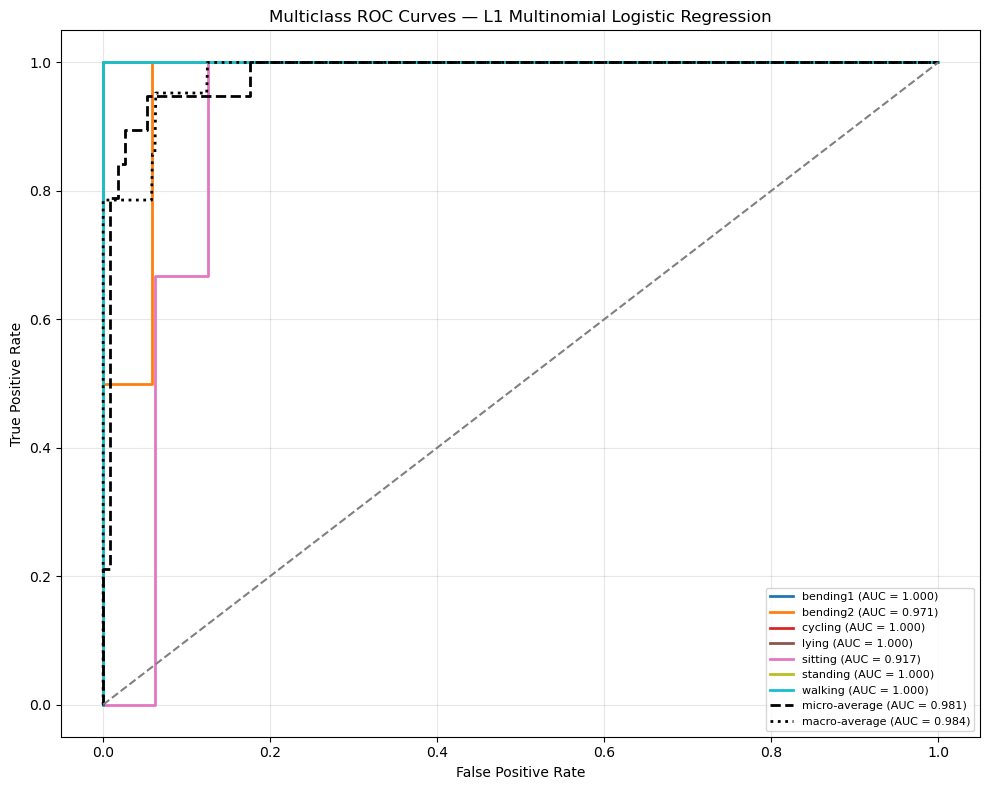

In [108]:
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

warnings.simplefilter("default", ConvergenceWarning)

multi_y_train = np.array([
    label for label, _, _ in train_instances
])

multi_y_test = np.array([
    label for label, _, _ in test_instances
])

multi_counts = pd.Series(multi_y_train).value_counts().sort_index()

print("Training instances per class:")
print(multi_counts.to_string())

print(
    "\nNote: bending2 has only 4 training instances, so one "
    "outer validation fold will contain no bending2 instances."
)

multi_l_values = list(range(1, 21))
multi_C_values = np.logspace(-2, 2, 8)

multi_outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

multi_inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

multi_outer_splits = list(
    multi_outer_cv.split(
        np.zeros((len(multi_y_train), 1)),
        multi_y_train
    )
)

multi_lr_settings = {
    "solver": "saga",
    "max_iter": 10000,
    "tol": 1e-3,
    "random_state": 42
}

multi_sklearn_version = tuple(
    int(part) for part in sklearn.__version__.split(".")[:2]
)

if multi_sklearn_version >= (1, 8):
    multi_lr_settings["l1_ratio"] = 1.0
else:
    multi_lr_settings["penalty"] = "l1"

multi_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(**multi_lr_settings))
])

multi_cv_results = []

# Select l using outer 5-fold CV.
for l in multi_l_values:
    X_l = np.array([
        extract_features_for_l(df, l)
        for _, _, df in train_instances
    ])

    fold_accuracies = []

    for train_idx, val_idx in multi_outer_splits:
        X_tr = X_l[train_idx]
        X_val = X_l[val_idx]

        y_tr = multi_y_train[train_idx]
        y_val = multi_y_train[val_idx]

        grid = GridSearchCV(
            estimator=multi_pipeline,
            param_grid={"clf__C": multi_C_values},
            cv=multi_inner_cv,
            scoring="accuracy",
            n_jobs=-1,
            refit=True
        )

        grid.fit(X_tr, y_tr)

        y_pred = grid.predict(X_val)
        fold_accuracies.append(
            accuracy_score(y_val, y_pred)
        )

    mean_accuracy = np.mean(fold_accuracies)

    multi_cv_results.append({
        "l": l,
        "cv_accuracy": mean_accuracy
    })

    print(
        f"l = {l:2d} | features = {X_l.shape[1]:3d} | "
        f"CV accuracy = {mean_accuracy:.4f}"
    )

multi_cv_df = pd.DataFrame(multi_cv_results)
multi_best_row = multi_cv_df.loc[
    multi_cv_df["cv_accuracy"].idxmax()
]

multi_best_l = int(multi_best_row["l"])
multi_best_cv_accuracy = float(multi_best_row["cv_accuracy"])

print("\n" + "=" * 60)
print(
    f"Best l = {multi_best_l}, "
    f"CV accuracy = {multi_best_cv_accuracy:.4f}"
)

multi_X_train_best = np.array([
    extract_features_for_l(df, multi_best_l)
    for _, _, df in train_instances
])

multi_final_grid = GridSearchCV(
    estimator=multi_pipeline,
    param_grid={"clf__C": multi_C_values},
    cv=multi_inner_cv,
    scoring="accuracy",
    n_jobs=-1,
    refit=True
)

multi_final_grid.fit(multi_X_train_best, multi_y_train)

multi_final_model = multi_final_grid.best_estimator_
multi_best_C = multi_final_grid.best_params_["clf__C"]

multi_X_test_best = np.array([
    extract_features_for_l(df, multi_best_l)
    for _, _, df in test_instances
])

multi_y_pred = multi_final_model.predict(multi_X_test_best)
multi_test_accuracy = accuracy_score(multi_y_test, multi_y_pred)

multi_classes = multi_final_model.named_steps["clf"].classes_

print(f"Best C = {multi_best_C:.6g}")
print(f"Test accuracy = {multi_test_accuracy:.4f}")
print(f"Test error = {1 - multi_test_accuracy:.4f}")

multi_cm = confusion_matrix(
    multi_y_test,
    multi_y_pred,
    labels=multi_classes
)

print("\nConfusion Matrix (Test Set):")
print(
    pd.DataFrame(
        multi_cm,
        index=multi_classes,
        columns=multi_classes
    ).to_string()
)

print("\nClassification Report:")
print(
    classification_report(
        multi_y_test,
        multi_y_pred,
        labels=multi_classes,
        zero_division=0
    )
)

multi_y_test_bin = label_binarize(
    multi_y_test,
    classes=multi_classes
)

multi_scores = multi_final_model.predict_proba(multi_X_test_best)

multi_fpr = {}
multi_tpr = {}
multi_roc_auc = {}

for i, name in enumerate(multi_classes):
    multi_fpr[name], multi_tpr[name], _ = roc_curve(
        multi_y_test_bin[:, i],
        multi_scores[:, i]
    )

    multi_roc_auc[name] = auc(
        multi_fpr[name],
        multi_tpr[name]
    )

multi_fpr["micro"], multi_tpr["micro"], _ = roc_curve(
    multi_y_test_bin.ravel(),
    multi_scores.ravel()
)

multi_roc_auc["micro"] = auc(
    multi_fpr["micro"],
    multi_tpr["micro"]
)

multi_roc_auc["macro"] = np.mean([
    multi_roc_auc[name] for name in multi_classes
])

multi_fpr_grid = np.linspace(0, 1, 1001)

multi_mean_tpr = np.mean([
    np.interp(
        multi_fpr_grid,
        multi_fpr[name],
        multi_tpr[name]
    )
    for name in multi_classes
], axis=0)

multi_fpr["macro"] = np.r_[0.0, multi_fpr_grid]
multi_tpr["macro"] = np.r_[0.0, multi_mean_tpr]

print(f"\nAUC (micro-average) = {multi_roc_auc['micro']:.4f}")
print(f"AUC (macro-average) = {multi_roc_auc['macro']:.4f}")

for name in multi_classes:
    print(f"AUC ({name}) = {multi_roc_auc[name]:.4f}")

plt.figure(figsize=(10, 8))
colors = plt.cm.tab10(np.linspace(0, 1, len(multi_classes)))

for color, name in zip(colors, multi_classes):
    plt.plot(
        multi_fpr[name],
        multi_tpr[name],
        color=color,
        lw=2,
        label=f"{name} (AUC = {multi_roc_auc[name]:.3f})"
    )

plt.plot(
    multi_fpr["micro"],
    multi_tpr["micro"],
    "k--",
    lw=2,
    label=f"micro-average (AUC = {multi_roc_auc['micro']:.3f})"
)

plt.plot(
    multi_fpr["macro"],
    multi_tpr["macro"],
    "k:",
    lw=2,
    label=f"macro-average (AUC = {multi_roc_auc['macro']:.3f})"
)

plt.plot([0, 1], [0, 1], color="gray", linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curves — L1 Multinomial Logistic Regression")
plt.legend(loc="lower right", fontsize=8)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Method.** L1-penalized multinomial logistic regression with the SAGA solver was used to classify all seven activities. For each l ∈ {1, 2, ..., 20}, each of the six time series was divided into l approximately equal-length segments, and seven time-domain features were extracted from each segment.

A pipeline combined standardization with logistic regression. Outer stratified 5-fold cross-validation evaluated each candidate l, while inner stratified 3-fold cross-validation selected C from eight logarithmically spaced values between 0.01 and 100. Standardization was fitted within each training fold to prevent preprocessing leakage.

The training set contains only four bending2 instances, so one outer validation fold contains no bending2 instances despite stratification. All outer training folds still contain all seven classes. After selecting l, C was selected again using 3-fold CV on the full training set, and the final pipeline was fitted.

**Results.**

| Metric | Value |
|--------|-------|
| Best l | 2 |
| Best C within the search grid | 100 |
| CV accuracy used to select l | 0.9143 |
| Test accuracy | 0.8421 |
| Test error | 0.1579 |
| AUC (micro-average) | 0.9806 |
| AUC (macro-average) | 0.9839 |

**Confusion Matrix (Test Set).** Rows represent actual activities, and columns represent predicted activities. Diagonal entries count correct predictions; off-diagonal entries count errors.

| Actual / Predicted | bending1 | bending2 | cycling | lying | sitting | standing | walking |
|--------------------|----------|----------|---------|-------|---------|----------|---------|
| bending1 | 2 | 0 | 0 | 0 | 0 | 0 | 0 |
| bending2 | 0 | 1 | 0 | 0 | 1 | 0 | 0 |
| cycling | 0 | 0 | 3 | 0 | 0 | 0 | 0 |
| lying | 0 | 0 | 0 | 3 | 0 | 0 | 0 |
| sitting | 1 | 0 | 0 | 0 | 1 | 1 | 0 |
| standing | 0 | 0 | 0 | 0 | 0 | 3 | 0 |
| walking | 0 | 0 | 0 | 0 | 0 | 0 | 3 |

The classifier correctly classified 16 of 19 test instances. The three errors were:

- One bending2 instance was predicted as sitting.
- One sitting instance was predicted as bending1.
- One sitting instance was predicted as standing.

**Multiclass ROC Curves and AUC.** A one-vs-rest approach was used: each activity was treated as the positive class, with the remaining six activities forming the negative class. Each ROC curve was constructed from the corresponding class probabilities.

| Activity | One-vs-rest AUC |
|----------|----------------|
| bending1 | 1.0000 |
| bending2 | 0.9706 |
| cycling | 1.0000 |
| lying | 1.0000 |
| sitting | 0.9167 |
| standing | 1.0000 |
| walking | 1.0000 |

The micro-average AUC pools all one-vs-rest decisions and equals 0.9806. The macro-average AUC is the unweighted mean of the seven per-class AUCs and equals 0.9839.

**Interpretation.** Sitting had the lowest test recall, with only one of its three instances classified correctly. Bending2 recall was 0.50. All test instances from the other five activities were correctly classified.

The high AUC values indicate strong one-vs-rest ranking performance, but they do not establish that the predicted probabilities are well calibrated. The CV score was used to select l and may be optimistic after model selection. The small test set also limits conclusions about performance on new observations.

#### ii. Naive Bayes

Classes: ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
Gaussian Naïve Bayes

[Gaussian NB] Best l = 1, CV accuracy = 0.8571
[Gaussian NB] Test accuracy = 0.8947, Test error = 0.1053

[Gaussian NB] Confusion Matrix:
          bending1  bending2  cycling  lying  sitting  standing  walking
bending1         2         0        0      0        0         0        0
bending2         0         2        0      0        0         0        0
cycling          0         0        3      0        0         0        0
lying            0         0        0      2        1         0        0
sitting          0         0        0      0        3         0        0
standing         0         0        0      0        1         2        0
walking          0         0        0      0        0         0        3

[Gaussian NB] Classification Report:
              precision    recall  f1-score   support

    bending1       1.00      1.00      1.00         2
    bending2       1.

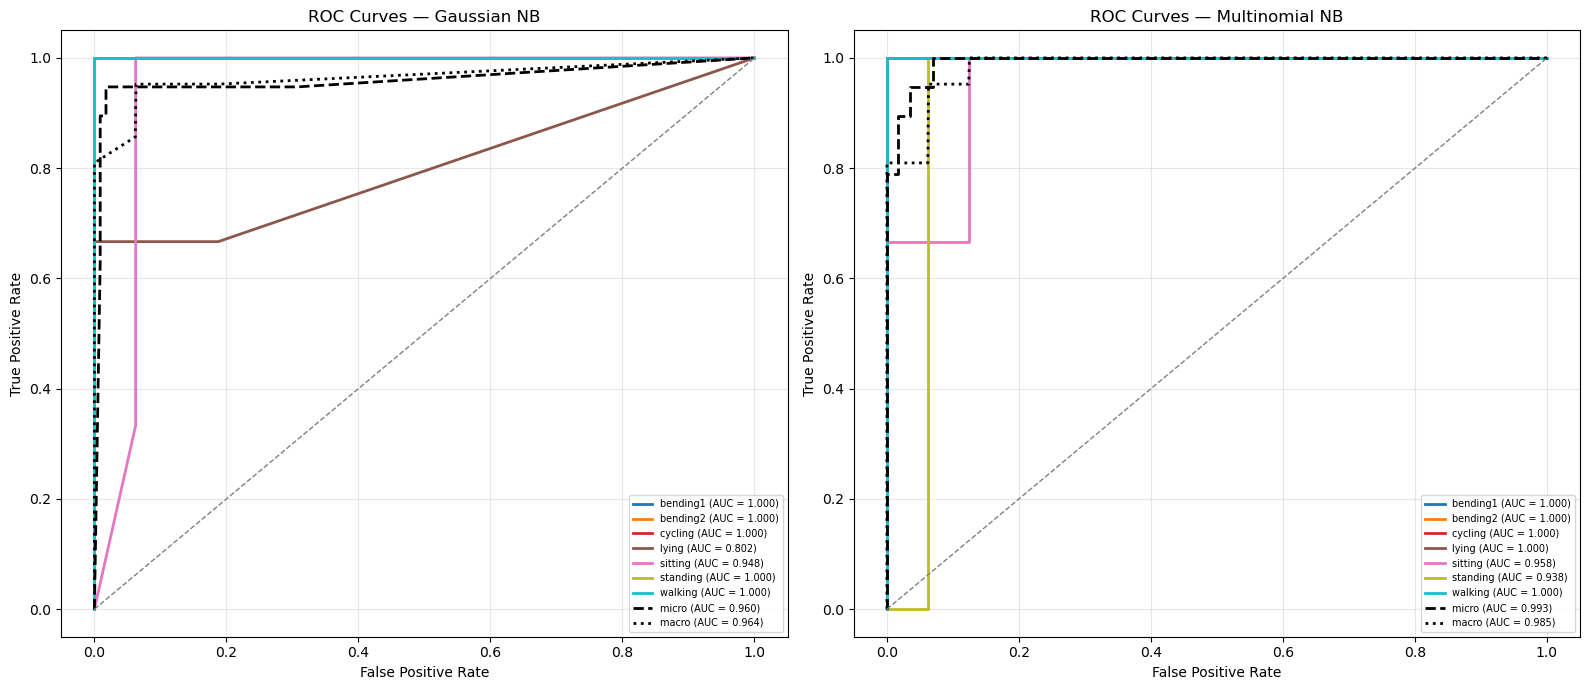


Summary Comparison
Gaussian NB:    best l = 1, test accuracy = 0.8947
Multinomial NB: best l = 1, test accuracy = 0.8947
Difference (Gaussian - Multinomial) = +0.0000


In [116]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.preprocessing import label_binarize
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, roc_curve, auc)
import warnings

warnings.simplefilter("default")

warnings.filterwarnings(
    "ignore",
    message=(
        r"The least populated class in y has only 4 members, "
        r"which is less than n_splits=5\."
    ),
    category=UserWarning,
    module=r"sklearn\.model_selection\._split"
)

SERIES_NAMES = ["avg_rss12", "var_rss12", "avg_rss13",
                "var_rss13", "avg_rss23", "var_rss23"]
FEATURE_NAMES = ["min", "max", "mean", "median", "std", "q1", "q3"]

def extract_features(series):
    return [np.min(series), np.max(series), np.mean(series),
            np.median(series), np.std(series, ddof=1),
            np.percentile(series, 25), np.percentile(series, 75)]

def extract_features_for_l(df, l):
    vec = []
    for col in SERIES_NAMES:
        values = df[col].values
        segments = np.array_split(values, l)
        for seg in segments:
            vec.extend(extract_features(seg))
    return vec

y_train_multi = np.array([lab for lab, _, _ in train_instances])
y_test_multi  = np.array([lab for lab, _, _ in test_instances])
classes = sorted(set(y_train_multi))
print("Classes:", classes)

l_values = list(range(1, 21))  

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
nb_cv_splits = list(
    outer_cv.split(
        np.zeros((len(y_train_multi), 1)),
        y_train_multi
    )
)

def evaluate_nb(model_class, X_train, y_train, X_test, y_test, tag):
    cv_results = []
    for l in l_values:
        X_l = np.array([extract_features_for_l(df, l)
                        for _, _, df in train_instances])
        fold_accs = []
        for train_idx, val_idx in nb_cv_splits:
            X_tr, X_val = X_l[train_idx], X_l[val_idx]
            y_tr, y_val = y_train[train_idx], y_train[val_idx]
            clf = model_class()
            clf.fit(X_tr, y_tr)
            fold_accs.append(accuracy_score(y_val, clf.predict(X_val)))
        mean_acc = np.mean(fold_accs)
        cv_results.append({"l": l, "cv_accuracy": mean_acc})
    cv_df = pd.DataFrame(cv_results)
    best_row = cv_df.loc[cv_df["cv_accuracy"].idxmax()]
    best_l = int(best_row["l"])
    print(f"\n[{tag}] Best l = {best_l}, CV accuracy = {best_row['cv_accuracy']:.4f}")

    X_train_best = np.array([extract_features_for_l(df, best_l)
                             for _, _, df in train_instances])
    X_test_best = np.array([extract_features_for_l(df, best_l)
                            for _, _, df in test_instances])
    final_model = model_class()
    final_model.fit(X_train_best, y_train)
    y_pred = final_model.predict(X_test_best)
    test_acc = accuracy_score(y_test, y_pred)
    print(f"[{tag}] Test accuracy = {test_acc:.4f}, Test error = {1 - test_acc:.4f}")

    cm = confusion_matrix(y_test, y_pred, labels=classes)
    print(f"\n[{tag}] Confusion Matrix:")
    print(pd.DataFrame(cm, index=classes, columns=classes).to_string())

    print(f"\n[{tag}] Classification Report:")
    print(classification_report(y_test, y_pred, labels=classes, zero_division=0))

    y_test_bin = label_binarize(y_test, classes=classes)
    y_score = final_model.predict_proba(X_test_best)
    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(len(classes)):
        fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
    fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

    roc_auc["macro"] = float(np.mean([
        roc_auc[i] for i in range(len(classes))
    ]))

    fpr_grid = np.linspace(0, 1, 1001)

    mean_tpr = np.mean([
        np.interp(fpr_grid, fpr[i], tpr[i])
        for i in range(len(classes))
    ], axis=0)

    fpr["macro"] = np.r_[0.0, fpr_grid]
    tpr["macro"] = np.r_[0.0, mean_tpr]

    print(f"[{tag}] AUC (micro) = {roc_auc['micro']:.4f}, "
          f"AUC (macro) = {roc_auc['macro']:.4f}")
    for i, cls in enumerate(classes):
        print(f"  AUC ({cls}) = {roc_auc[i]:.4f}")

    return best_l, test_acc, cm, roc_auc, fpr, tpr

print("=" * 60)
print("Gaussian Naïve Bayes")
print("=" * 60)
best_l_gauss, acc_gauss, cm_gauss, auc_gauss, fpr_gauss, tpr_gauss = \
    evaluate_nb(GaussianNB, None, y_train_multi, None, y_test_multi, "Gaussian NB")

print("\n" + "=" * 60)
print("Multinomial Naïve Bayes")
print("=" * 60)
best_l_multi, acc_multi, cm_multi, auc_multi, fpr_multi, tpr_multi = \
    evaluate_nb(MultinomialNB, None, y_train_multi, None, y_test_multi, "Multinomial NB")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))

for ax, (fpr, tpr, auc_vals, title) in zip(
        axes,
        [(fpr_gauss, tpr_gauss, auc_gauss, "Gaussian NB"),
         (fpr_multi, tpr_multi, auc_multi, "Multinomial NB")]):
    for i, cls in enumerate(classes):
        ax.plot(fpr[i], tpr[i], color=colors[i], lw=2,
                label=f"{cls} (AUC = {auc_vals[i]:.3f})")
    ax.plot(fpr["micro"], tpr["micro"], 'k--', lw=2,
            label=f"micro (AUC = {auc_vals['micro']:.3f})")
    ax.plot(fpr["macro"], tpr["macro"], 'k:', lw=2,
            label=f"macro (AUC = {auc_vals['macro']:.3f})")
    ax.plot([0, 1], [0, 1], 'gray', lw=1, linestyle='--')
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"ROC Curves — {title}")
    ax.legend(loc="lower right", fontsize=7)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("Summary Comparison")
print("=" * 60)
print(f"Gaussian NB:    best l = {best_l_gauss}, test accuracy = {acc_gauss:.4f}")
print(f"Multinomial NB: best l = {best_l_multi}, test accuracy = {acc_multi:.4f}")
print(f"Difference (Gaussian - Multinomial) = {acc_gauss - acc_multi:+.4f}")

**Method.** Seven-class activity classification was performed using Gaussian Naïve Bayes and Multinomial Naïve Bayes. For each model, l ∈ {1, 2, ..., 20} was evaluated using stratified 5-fold cross-validation. Both models used the same folds, and seven time-domain features were extracted from each segment of each time series.

Because the training set contains only four bending2 instances, one validation fold contains no bending2 instances despite stratification. After selecting l, each model was fitted on all training instances and evaluated on the held-out test set.

**Results.**

| Model | Best l | CV Accuracy | Test Accuracy | Test Error | Micro AUC | Macro AUC |
|-------|--------|-------------|---------------|------------|-----------|-----------|
| Gaussian NB | 1 | 0.8571 | 0.8947 | 0.1053 | 0.9596 | 0.9643 |
| Multinomial NB | 1 | 0.8549 | 0.8947 | 0.1053 | 0.9926 | 0.9851 |

Both models selected l = 1 and correctly classified 17 of the 19 test instances. Thus, full-length time-series features achieved the highest CV accuracy among the segmentation choices evaluated for each model.

**Confusion Matrices.** Rows represent actual activities, and columns represent predicted activities. Each model made two test errors:

- Gaussian NB: one lying instance was predicted as sitting, and one standing instance was predicted as sitting.
- Multinomial NB: one sitting instance was predicted as standing, and one standing instance was predicted as lying.

All bending1, bending2, cycling, and walking test instances were correctly classified by both models.

**ROC Curves and AUC.** One-vs-rest ROC curves were constructed for all seven activities. Micro AUC pools the one-vs-rest decisions, while macro AUC is the unweighted mean of the seven per-class AUCs.

Multinomial NB achieved higher micro and macro AUC values than Gaussian NB, indicating stronger ranking performance under these evaluation measures. This does not establish better probability calibration, and the higher AUC did not produce higher classification accuracy at the models’ default decision rules.

**Distributional Assumptions.** Gaussian NB assumes that each feature follows a Gaussian distribution within each class. It is a natural baseline for continuous features, although continuous measurements do not automatically satisfy the Gaussian assumption.

Multinomial NB uses a model designed for count-like feature vectors. The extracted features are non-negative but contain continuous summaries, so this is an empirical application of the model rather than a literal count-data setting.

Both methods assume conditional independence of features given the activity class. Statistics extracted from the same signal, such as the mean, median, and quartiles, may be correlated, making this assumption restrictive.

**Interpretation.** The two models tied in observed test accuracy. Gaussian NB had a slightly higher CV accuracy, while Multinomial NB achieved higher test AUC values. These results do not establish a clear overall winner between the two variants. The small test set and the use of CV scores to select l limit conclusions about future performance.

#### iii. Comparison

**Results.** The three multiclass classifiers produced the following results:

| Method | Best l | Reported CV Accuracy | Test Accuracy | Test Error | Micro AUC | Macro AUC |
|--------|--------|----------------------|---------------|------------|-----------|-----------|
| L1-penalized multinomial logistic regression | 2 | 0.9143 | 0.8421 | 0.1579 | 0.9806 | 0.9839 |
| Gaussian Naïve Bayes | 1 | 0.8571 | 0.8947 | 0.1053 | 0.9596 | 0.9643 |
| Multinomial Naïve Bayes | 1 | 0.8549 | 0.8947 | 0.1053 | 0.9926 | 0.9851 |

**Test-Set Performance.** Gaussian NB and Multinomial NB tied for the highest test accuracy, correctly classifying 17 of 19 instances. L1-penalized multinomial logistic regression correctly classified 16 of 19 instances. Thus, both Naïve Bayes models achieved a lower observed test error than logistic regression.

Multinomial NB also achieved the highest micro and macro AUC values. These results indicate stronger ranking performance on this test set, although they do not establish better probability calibration.

**Cross-Validation.** L1-penalized multinomial logistic regression had the highest reported CV accuracy. However, these scores were used to select the segmentation level l, and the logistic regression procedure additionally used inner CV to select C. The reported scores should therefore not be treated as unbiased, directly matched estimates of future performance.

The higher CV score for logistic regression and the higher test accuracy for Naïve Bayes reflect different outcomes on the available validation and test observations. Neither result alone establishes consistent superiority on new data.

**Overall Assessment.** Based on observed test classification accuracy, Gaussian NB and Multinomial NB performed equally best. Considering both test accuracy and AUC, Multinomial NB had the strongest combined test results in this experiment.

However, its accuracy advantage over logistic regression corresponds to only one test instance. With just 19 test observations, these results provide limited evidence about which method will perform best more generally.

## 3. ISLR 4.8.3

### 1. Bayes' Decision Rule
The Bayes' classifier assigns an observation $x$ to the class $k$ that maximizes the posterior probability:
$$P(Y=k | X=x) = \frac{\pi_k f_k(x)}{\sum_{j=1}^K \pi_j f_j(x)}$$
where $\pi_k = P(Y=k)$ is the prior probability for class $k$. 

Since the denominator $\sum_{j=1}^K \pi_j f_j(x)$ is identical for all classes, maximizing the posterior probability is equivalent to maximizing the numerator $\pi_k f_k(x)$. For mathematical convenience, we can maximize the natural logarithm of the numerator: $\log(\pi_k f_k(x))$.

### 2. Gaussian Density Function
The probability density function for a one-dimensional normal distribution $N(\mu_k, \sigma_k^2)$ is:
$$f_k(x) = \frac{1}{\sqrt{2\pi\sigma_k^2}} \exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right)$$

Taking the natural logarithm of $\pi_k f_k(x)$, we get the discriminant function $\delta_k(x)$:
$$\delta_k(x) = \log(\pi_k) + \log(f_k(x))$$
$$\delta_k(x) = \log(\pi_k) - \frac{1}{2}\log(2\pi) - \frac{1}{2}\log(\sigma_k^2) - \frac{(x-\mu_k)^2}{2\sigma_k^2}$$

### 3. Expanding and Rearranging Terms
We can drop the constant term $-\frac{1}{2}\log(2\pi)$ because it does not depend on $k$ and will not affect the comparison between classes. 

Let's expand the squared term $(x-\mu_k)^2 = x^2 - 2x\mu_k + \mu_k^2$:
$$\delta_k(x) = \log(\pi_k) - \frac{1}{2}\log(\sigma_k^2) - \frac{x^2 - 2x\mu_k + \mu_k^2}{2\sigma_k^2}$$

Now, let's group the terms by powers of $x$:
$$\delta_k(x) = \left(-\frac{1}{2\sigma_k^2}\right)x^2 + \left(\frac{\mu_k}{\sigma_k^2}\right)x + \left(\log(\pi_k) - \frac{1}{2}\log(\sigma_k^2) - \frac{\mu_k^2}{2\sigma_k^2}\right)$$

This can be written in the general quadratic form $A_k x^2 + B_k x + C_k$, where:
*   $A_k = -\frac{1}{2\sigma_k^2}$
*   $B_k = \frac{\mu_k}{\sigma_k^2}$
*   $C_k = \log(\pi_k) - \frac{1}{2}\log(\sigma_k^2) - \frac{\mu_k^2}{2\sigma_k^2}$

### 4. Decision Boundary Analysis
To find the decision boundary between any two classes, say class $k$ and class $l$, we set their discriminant functions equal to each other:
$$\delta_k(x) = \delta_l(x)$$
$$A_k x^2 + B_k x + C_k = A_l x^2 + B_l x + C_l$$
$$(A_k - A_l)x^2 + (B_k - B_l)x + (C_k - C_l) = 0$$

Because the problem explicitly states that we do **not** assume equal variances (i.e., $\sigma_k^2 \neq \sigma_l^2$), the coefficients of the $x^2$ terms are different ($A_k \neq A_l$). 

Since $A_k - A_l \neq 0$, the $x^2$ term does not cancel out. The equation $(A_k - A_l)x^2 + (B_k - B_l)x + (C_k - C_l) = 0$ is a quadratic equation in $x$. 

### Conclusion
The decision boundary is defined by a quadratic equation, meaning the Bayes' classifier produces a non-linear, quadratic decision boundary. 

*(Note: If we had assumed equal variances $\sigma_1^2 = \dots = \sigma_K^2 = \sigma^2$ as in LDA, then $A_k = A_l$, the $x^2$ terms would cancel out, and the decision boundary would reduce to a linear equation $B_k x + C_k = B_l x + C_l$.)*

## 4. ISLR 4.8.7

We want to find $P(\text{Yes} | X=4)$. According to Bayes' theorem:
$$P(\text{Yes} | X=4) = \frac{P(X=4 | \text{Yes}) P(\text{Yes})}{P(X=4 | \text{Yes}) P(\text{Yes}) + P(X=4 | \text{No}) P(\text{No})}$$

**Given parameters:**
*   Prior probabilities: $P(\text{Yes}) = 0.8$, $P(\text{No}) = 0.2$
*   Class-conditional means: $\mu_{\text{Yes}} = 10$, $\mu_{\text{No}} = 0$
*   Common variance: $\sigma^2 = 36 \implies \sigma = 6$
*   Observed value: $X = 4$

We calculate the likelihoods $P(X=4 | \text{Yes})$ and $P(X=4 | \text{No})$ using the normal density function. 

$$P(X=4 | \text{Yes}) = \frac{1}{\sqrt{2\pi \cdot 36}} \exp\left(-\frac{(4 - 10)^2}{2 \cdot 36}\right) = \frac{1}{6\sqrt{2\pi}} e^{-36/72} = \frac{1}{6\sqrt{2\pi}} e^{-0.5}$$

$$P(X=4 | \text{No}) = \frac{1}{\sqrt{2\pi \cdot 36}} \exp\left(-\frac{(4 - 0)^2}{2 \cdot 36}\right) = \frac{1}{6\sqrt{2\pi}} e^{-16/72} = \frac{1}{6\sqrt{2\pi}} e^{-2/9}$$

Notice that the constant factor $\frac{1}{6\sqrt{2\pi}}$ will cancel out in the numerator and denominator of Bayes' theorem. We can simplify the calculation by using this fact.

In [75]:
import numpy as np
from scipy.stats import norm

# Given parameters
mu_yes = 10
mu_no = 0
variance = 36
sigma = np.sqrt(variance)

prior_yes = 0.8
prior_no = 0.2

x_observed = 4

# Calculate likelihoods P(X=4 | Yes) and P(X=4 | No)
# Note: For continuous variables, we use the probability density function (PDF)
likelihood_yes = norm.pdf(x_observed, loc=mu_yes, scale=sigma)
likelihood_no = norm.pdf(x_observed, loc=mu_no, scale=sigma)

# Apply Bayes' Theorem
numerator = likelihood_yes * prior_yes
denominator = (likelihood_yes * prior_yes) + (likelihood_no * prior_no)

posterior_yes = numerator / denominator

print(f"Likelihood of X=4 given Yes: {likelihood_yes:.5f}")
print(f"Likelihood of X=4 given No:  {likelihood_no:.5f}")
print(f"Posterior Probability P(Yes | X=4): {posterior_yes:.4f} ({posterior_yes * 100:.2f}%)")

# Manual verification (dropping the constant factor)
import math
likelihood_yes_simplified = math.exp(-0.5)
likelihood_no_simplified = math.exp(-2/9)
posterior_yes_manual = (prior_yes * likelihood_yes_simplified) / ((prior_yes * likelihood_yes_simplified) + (prior_no * likelihood_no_simplified))
print(f"Manual calculation: {posterior_yes_manual:.4f}")

Likelihood of X=4 given Yes: 0.04033
Likelihood of X=4 given No:  0.05324
Posterior Probability P(Yes | X=4): 0.7519 (75.19%)
Manual calculation: 0.7519


## Conclusion
The probability that a company will issue a dividend this year given that its percentage profit was $X=4$ last year is approximately **75.19%**.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9